In [2]:
import sys,os
os.environ['pRT_input_data_path'] = '/Users/nasedkin/testing/input_data/'
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import matplotlib.pyplot as plt
import copy as cp

#from numba import jit
from jax import config
config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax import grad, jit, vmap, lax

import petitRADTRANS.physical_constants as cst 
from petitRADTRANS.fortran_radtrans_core import fortran_radtrans_core as fs
from petitRADTRANS.fortran_radtrans_core import math, cloud_utils, physics
from petitRADTRANS.radtrans import Radtrans
from petitRADTRANS.retrieval.parameter import Parameter
from petitRADTRANS.retrieval.models import emission_model_diseq, guillot_emission
import petitRADTRANS.plotlib.style as ps
ps.set_petitradtrans_plot_style()
path_input_data = "/Users/nasedkin/python-packages/petitRADTRANS/input_data/"
buffer = np.genfromtxt(os.path.join(path_input_data, 'opa_input_files', 'g_comb_grid.dat'))


N_pressures = 20
N_frequency = 50
N_species = 2
N_ckg = 16

gravity = 10**4

pressure_unit = 1e6
pressures = 1e6*np.logspace(-6,3,N_pressures)

wavelength_min = 1.0
wavelength_max = 5.0
micron_to_meter = 1e-4

jax_pressures = 1e6*jnp.logspace(-6,3,20)
jax_gravity = 10**4
jax_total_opacity = jnp.ones((N_ckg,N_frequency,N_species,N_pressures))
jax_total_opacity_transpose = jnp.ones((N_ckg,N_frequency,N_species,N_pressures)).T
jax_continuum_opacities = jnp.ones((N_frequency,N_pressures))
jax_frequency_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,N_frequency+1)*micron_to_meter)
jax_frequency_bin_centers = (jax_frequency_bin_edges[:-1]+jax_frequency_bin_edges[1:])*0.5
jax_wgauss = jnp.array(buffer[:,1])

line_opacities_grid = np.ones((N_ckg,N_frequency,N_species,N_pressures))
line_opacities_transpose = np.ones((N_ckg,N_frequency,N_species,N_pressures)).T
continuum_opacities_grid = np.ones((N_pressures,N_frequency))
continuum_opacities_transpose = continuum_opacities_grid.T
frequency_bin_edges = cst.c/(np.linspace(wavelength_min,wavelength_max,N_frequency+1)*micron_to_meter)
frequency_bin_centers = (frequency_bin_edges[:-1]+frequency_bin_edges[1:])*0.5
w_gauss = buffer[:,1]

def py_compute_species_optical_depths(gravity,press,total_kappa):
    """
    calc_tau_g_tot_ck


    Args:
        gravity (float): surface gravity in cgs units
        press (np.ndarray): pressure in each level in cgs
        total_kappa (np.ndarray): total_kappa(g_len,freq_len,N_species,struc_len)

    Returns:
        tau: total correlated k opacity
    """
    tau = np.zeros(total_kappa.shape)
    struc_len = total_kappa.shape[3]
    for i_struc in range(1,struc_len):
        tau[i_struc] = tau[i_struc-1] +\
             (total_kappa[i_struc]+total_kappa[i_struc-1])\
             /2.0/gravity*(press[i_struc]-press[i_struc-1])
    return tau


Using pRT Plotting style!


In [20]:
%timeit py_compute_species_optical_depths(gravity,pressures,line_opacities_transpose)


310 µs ± 13.4 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [57]:
%timeit fs.compute_species_optical_depths(gravity, pressures, line_opacities_grid)
%timeit fs.compute_optical_depths(gravity, pressures,line_opacities_grid[:,:,:1,:], True, continuum_opacities_transpose)


74.1 µs ± 1.18 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
112 µs ± 559 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [ ]:
@jit
def compute_optical_depths(gravity,pressure,total_opacity):
    """_summary_

    Args:
        gravity (float): Surface gravity in cgs (cm/s^2)
        pressure (ndarray): 1D array of pressures in pascal
        total_opacity (ndarray): kappa, has shape (g_len, freq_len, press_len)
                                 This is the sum of all species' opacities, at 
                                 every c-k g coordinate, frequency and pressure.

    Returns:
        transmission: Tau, a 1D array of transmission coefficients for g, 
                      frequency and for every pressure level in the atmosphere.
    """
    transmission = jnp.zeros(total_opacity.shape)
    for i_struc in range(1,total_opacity.shape[3]):
        transmission = transmission.at[i_struc].set(transmission[i_struc-1] +\
                       (total_opacity[i_struc]+total_opacity[i_struc-1])\
                        /2.0/gravity*(pressure[i_struc]-pressure[i_struc-1]))
    return transmission

@jit
def calc_photon_destruction_prob(gravity,
                                 pressure,
                                 total_opacity_in,
                                 continuum_opacity_scat_emis):
    """_summary_

    Args:
        gravity (float): Surface gravity in cgs (cm/s^2)
        pressure (ndarray):1D array of pressures in pascal
        total_opacity_in (ndarray): kappa, has shape (g_len, freq_len, press_len)
                                    This is the sum of all species' opacities, at 
                                    every c-k g coordinate, frequency and pressure.
        continuum_opacity_scat_emis (ndarray): The continuum opacity, which is constant 
                                                in g, for every frequency and pressure.
                                                This includes clouds, Rayleigh and CIA
                                                opacities.

    Returns:
        photon_destruction_prob: probability that the photon DOESN'T leave the atmospheric layer
    """
    total_opacity = total_opacity_in[:,:,0,:]
    g_len = total_opacity_in.shape[0]
    photon_destruction_prob = jnp.ones(total_opacity.shape)
    for i_g in range(g_len):
        total_opacity = total_opacity.at[i_g].set(total_opacity[i_g] + continuum_opacity_scat_emis)
        photon_destruction_prob = photon_destruction_prob.at[i_g].set(continuum_opacity_scat_emis/total_opacity[i_g])
    photon_destruction_prob = 1 - photon_destruction_prob
    return photon_destruction_prob

@jit
def transmission_g_tot_ck_scat(gravity,
                          pressure,
                          total_opacity_in,
                          continuum_opacity_scattering_emis):
    """_summary_

    Args:
        gravity (_type_): _description_
        pressure (_type_): _description_
        total_opacity_in (_type_): _description_
        continuum_opacity_scattering_emis (_type_): _description_

    Returns:
        _type_: _description_
    """
    photon_destruction_prob = calc_photon_destruction_prob(gravity, 
                                                           
                                                           pressure,
                                                           total_opacity_in,
                                                           continuum_opacity_scattering_emis)
    transmission = compute_optical_depths(gravity,
                                       pressure,
                                       total_opacity_in)
    return transmission, photon_destruction_prob

@jit
def compute_rosseland_opacities_core(clouds_final_absorption_opacities,
                                     frequencies_bin_edges,
                                     temperature,
                                     weights_gauss):
    """Calculate the Rosseland mean opacity as a function of temperature.

    Args:
        clouds_final_absorption_opacities (DeviceArray): Absorption opacities with shape (N_g, N_frequency_edges - 1, N_temperature).
        frequencies_bin_edges (DeviceArray): Frequency bin edges with shape (N_frequency_edges,).
        temperature (DeviceArray): Temperature with shape (N_temperature,).
        weights_gauss (DeviceArray): Gauss weights with shape (N_g,).

    Returns:
        DeviceArray: Rosseland opacity with shape (N_temperature,).
    """
    diff_freqs = frequencies_bin_edges[:-1] - frequencies_bin_edges[1:]
    B_nu_dT = compute_planck_function_temperature_derivative(temperature, frequencies_bin_edges)

    # Precompute for efficiency
    inv_absorption_opacities = 1.0 / clouds_final_absorption_opacities

    # Use einsum for efficient contraction
    weighted_inv_opacities = jnp.einsum('g,gfn->fn', weights_gauss, inv_absorption_opacities)

    kappa_rosse = jnp.sum(B_nu_dT * weighted_inv_opacities * diff_freqs[:, None], axis=0)
    numerator = jnp.sum(B_nu_dT * diff_freqs[:, None], axis=0)

    return numerator / kappa_rosse

def compute_rosseland_opacity(opacities, 
                              temperature, 
                              weights_gauss, 
                              frequencies_bin_edges, 
                              scattering_in_emission, 
                              continuum_opacities_scattering):
    """_summary_

    Args:
        total_opacity (_type_): _description_
        temperature (_type_): _description_
        w_gauss (_type_): _description_
        border_freqs (_type_): _description_
        do_scat_emis (_type_): _description_
        continuum_opacity_scattering_emis (_type_): _description_

    Returns:
        _type_: _description_
    """

    if scattering_in_emission:
        opacities_use = opacities + continuum_opacities_scattering[None,:,:]
    else:
        opacities_use = opacities

    kappa_rosse = compute_rosseland_opacities_core(opacities_use, 
                                                   frequencies_bin_edges, 
                                                   temperature,
                                                   weights_gauss)
    return kappa_rosse
rosseland_opacity = jit(compute_rosseland_opacity,static_argnums=(4))

def _planck_opacity(total_opacity, 
                      temperature, 
                      w_gauss, 
                      border_freqs,
                      do_scat_emis, 
                      continuum_opacity_scattering_emis):
    """_summary_

    Args:
        total_opacity (_type_): _description_
        temperature (_type_): _description_
        w_gauss (_type_): _description_
        border_freqs (_type_): _description_
        do_scat_emis (_type_): _description_
        continuum_opacity_scattering_emis (_type_): _description_

    Returns:
        _type_: _description_
    """
    if do_scat_emis:
        total_opacity_use = total_opacity + continuum_opacity_scattering_emis[None,:,:]
    else:
        total_opacity_use = total_opacity
    kappa_planck = calc_planck_opa(total_opacity_use[:,:,:], 
                                   border_freqs, 
                                   temperature,
                                   w_gauss)
    return kappa_planck
planck_opacity = jit(_planck_opacity,static_argnums=(4))



@jit
def calc_planck_opa(total_opacity,
                    border_freqs,
                    temperature,
                    w_gauss):
    """_summary_

    Args:
        total_opacity (_type_): _description_
        border_freqs (_type_): _description_
        temperature (_type_): _description_
        w_gauss (_type_): _description_

    Returns:
        _type_: _description_
    """
    diff_freqs = jnp.diff(border_freqs)
    B_nu = star_planck(temperature,border_freqs)

    kappa_planck= jnp.sum(B_nu *jnp.sum(w_gauss[:,None,None]/total_opacity[:,:-1,:],axis=0) *diff_freqs[:,None],axis=0)
    norm = jnp.sum(B_nu * diff_freqs[:,None], axis = 0)
    return kappa_planck / norm

@jit
def flux_ck_contribution(frequency,
                         transmission,
                         temperature,
                         scat_angle,
                         w_gauss_scat_angle,
                         w_gauss):
    """_summary_

    Args:
        frequency (_type_): _description_
        transmission (_type_): _description_
        temperature (_type_): _description_
        scat_angle (_type_): mu, the cosine of the scattering angle
        w_gauss_scat_angle (_type_): _description_
        w_gauss (_type_): _description_

    Returns:
        _type_: _description_
    """

    struct_shape = (frequency.shape[0],temperature.shape[0])
    flux = jnp.zeros(struct_shape[0])
    contr_em = jnp.zeros(struct_shape)

    for i_scat_angle in range(scat_angle.shape[0]):
        # Transmissions for a given incidence angle
        transm_mu = jnp.exp(-transmission/scat_angle[i_scat_angle])

        # Flux contribution from given scat_angle-angle

        #mean_transm = np.zeros((struct_shape[0],transmission.shape[2],struct_shape[1])
        mean_transm = jnp.sum(transm_mu* w_gauss[:, None, None, None], axis=0)
        transm_all = jnp.prod(mean_transm, axis=1)

        r = planck_f(temperature,frequency)
        # Do the actual radiative transport
        flux_mu = jnp.sum((r[:,:-1]+r[:,1:])*(transm_all[:,0:-1]-transm_all[:,1:])/2.0,axis=1)      
        flux_mu = jnp.add(flux_mu,r[:,struct_shape[1]]*transm_all[:,struct_shape[1]])

        contr_em = contr_em.at[:,:-1].add((r[:,:-1]+r[:,1:])*(transm_all[:,0:-1]-transm_all[:,1:]) *\
                                           scat_angle[i_scat_angle]*w_gauss_scat_angle[i_scat_angle])     
        contr_em = contr_em.at[:,-1].add(2.0*r[:,struct_shape[1]] * transm_all[:,struct_shape[1]] *\
                                          scat_angle[i_scat_angle]*w_gauss_scat_angle[i_scat_angle])

        # angle integ, factor 1/2 needed for flux calc. from upward pointing intensity
        flux = jnp.add(flux, flux_mu/2.0*scat_angle[i_scat_angle]*w_gauss_scat_angle[i_scat_angle])

    #Normalization
    flux = flux*4.0*jnp.pi
    contr_em = contr_em.T
    contr_em = jnp.divide(contr_em,jnp.sum(contr_em,axis=0))
    return flux, contr_em

@jit
def flux_ck(frequency,
            transmission,
            temperature,
            scat_angle,
            w_gauss_scat_angle,
            w_gauss):
    """_summary_

    Args:
        frequency (ndarray): shape (len_freq)
        transmission (ndarray): shape (len_g, len_freq, len_spec, len_temp))
        temperature (ndarray): shape (len_temp)
        scat_angle (ndarray): shape (len_scatter)
        w_gauss_scat_angle (ndarray): shape (len_scatter)
        w_gauss (ndarray): shape (len_scatter)

    Returns:
        flux: shape (len_freq)
    """
    struct_shape = (frequency.shape[0],temperature.shape[0])
    flux = jnp.zeros(struct_shape[0])
    for i_mu in range(scat_angle.shape[0]):
        # Transmissions for a given incidence angle
        transm_mu= jnp.exp(-transmission/scat_angle[i_mu])
        mean_transm = jnp.sum(transm_mu* w_gauss[:, None, None, None], axis=0)
        transm_all = jnp.prod(mean_transm, axis=1)

        r = planck_f(temperature,frequency)
        # Do the actual radiative transport
        flux_mu = jnp.sum((r[:,:-1]+r[:,1:])*(transm_all[:,0:-1]-transm_all[:,1:])*0.5,axis=1)      
        flux_mu = jnp.add(flux_mu,r[:,struct_shape[1]]*transm_all[:,struct_shape[1]])
        #print(flux_mu.shape)
        # angle integ, factor 1/2 needed for flux calc. from upward pointing intensity
        flux = jnp.add(flux,flux_mu*0.5*scat_angle[i_mu]*w_gauss_scat_angle[i_mu])
    #Normalization
    return flux*4.0*jnp.pi

@jit
def planck_f(T,nu):
    """
    Calculates B_ν https://en.wikipedia.org/wiki/Planck%27s_law
    For every temperature and frequency provided.

    Args:
        T (ndarray): 1D array of temperature in Kelvin
        nu (ndarray): 1D array of frequencies in Hertz

    Returns:
        B_nu (ndarray): (len(nu),len(T)) matrix of the spectral radiance (ie flux) as calculated from 
                        Planck's law for each frequency and temperature.
    """
    T_use = jnp.tile(T,(nu.shape[0],1))
    buffer = 2.0*cst.h*nu[:,None]**3/cst.c**2
    B_nu = buffer / (jnp.exp(cst.h*nu[:,None]/(cst.kB*T_use))-1.0)
    return B_nu

@jit
def compute_planck_function_temperature_derivative(T, frequency_bin_edges):
    """
    Calculates the gradient of B_ν (Planck's Law) with respect to temperature for 
    each temperature and frequency provided using JAX.

    Args:
        T (DeviceArray): 1D JAX array of temperatures in Kelvin.
        frequency_bin_edges (DeviceArray): 1D JAX array of frequency bin edges in Hertz.

    Returns:
        B_nu_dT (DeviceArray): (len(T), len(nu)) JAX array of the derivative of the spectral radiance.
    """
    nu = (frequency_bin_edges[:-1] + frequency_bin_edges[1:]) * 0.5  # Calculate midpoints directly

    # Constants for efficiency (avoid repeated calculations within the loop)
    h_over_kb = cst.h / cst.kB
    two_h_over_c2 = 2.0 * cst.h**2 / cst.c**2
    
    # Vectorized calculation of exp_terms and denominator for all T and nu
    exp_arg = (h_over_kb * jnp.outer(0.5/T, nu))
    exp_term_pos = jnp.exp(exp_arg) 
    exp_term_neg = jnp.exp(-exp_arg)

    denominator = (exp_term_pos - exp_term_neg)**2 * jnp.outer(cst.kB * T**2, jnp.ones_like(nu)) 

    # Calculate B_nu_dT using outer product for broadcasting, then transpose
    B_nu_dT = (two_h_over_c2 * jnp.outer(jnp.ones_like(T), nu**4) / denominator).T  # Correct broadcasting
    return B_nu_dT

@jit
def star_planck(T,nu):
    """
    Calculates B_ν https://en.wikipedia.org/wiki/Planck%27s_law
    For every temperature and frequency provided. 
    Approximates the integral using Boole's method

    Args:
        T (ndarray): 1D array of temperature in Kelvin
        nu (ndarray): 1D array of frequencies in Hertz

    Returns:
        B_nu (ndarray): (len(nu),len(T)) matrix of the spectral radiance (ie flux) as calculated from 
                        Planck's law for each frequency and temperature.
    """
    frequency_len = nu.shape[0]
    bnus = []
    # Take mean using Boole's method
    for i in range(frequency_len-1):
        nu_large = jnp.max(nu[i:i+1])
        nu_small = jnp.min(nu[i:i+1])
        nu1 = nu_small
        nu2 = nu_small+1.0*(nu_large-nu_small)/4.0
        nu3 = nu_small+2.0*(nu_large-nu_small)/4.0
        nu4 = nu_small+3.0*(nu_large-nu_small)/4.0
        nu5 = nu_large
        val = 1.0/90.0*\
            ((7.0* 2.0*cst.h*nu1**3)/(cst.c**2.0*(jnp.exp(cst.h*nu1/(cst.kB*T))-1.0)) +\
            (32.0*2.0*cst.h*nu2**3)/(cst.c**2.0*(jnp.exp(cst.h*nu2/(cst.kB*T))-1.0)) +\
            (12.0*2.0*cst.h*nu3**3)/(cst.c**2.0*(jnp.exp(cst.h*nu3/(cst.kB*T))-1.0) )+\
            (32.0*2.0*cst.h*nu4**3)/(cst.c**2.0*(jnp.exp(cst.h*nu4/(cst.kB*T))-1.0)) +\
            (7.0* 2.0*cst.h*nu5**3)/(cst.c**2.0*(jnp.exp(cst.h*nu5/(cst.kB*T))-1.0)))
        bnus.append(val)
    B_nu = jnp.array(bnus)
    return B_nu


317 μs ± 14.3 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
394 μs ± 5.31 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


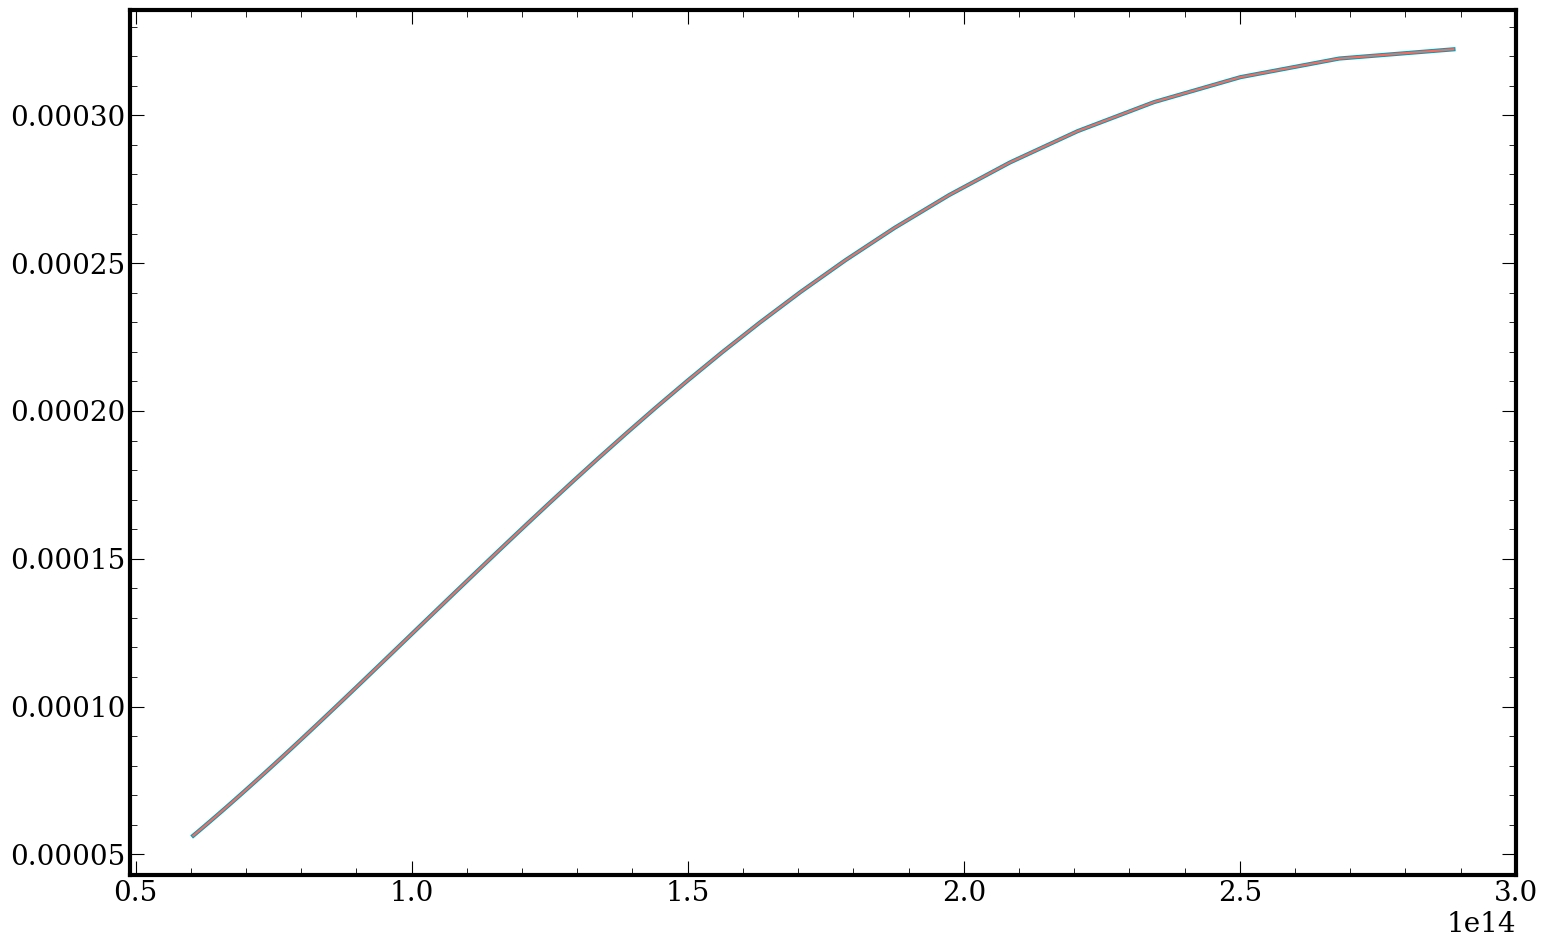

In [5]:
T_min = 500.0
T_max = 5000.0
wavelength_min = 1.0
wavelength_max = 5.0
micron_to_meter = 1e-4
jax_temperatures = jnp.linspace(T_min,T_max,N_pressures)
temperatures = np.linspace(T_min,T_max,N_pressures)
min_opacity_frequency = 0.1
max_opacity_frequency = 10.0
min_opacity_pressure = 1e-4
max_opacity_pressure = 1e-2

bnus = np.zeros(N_frequency-1)

jax_total_opacity_linear = jnp.ones((N_ckg,N_frequency,N_species,N_pressures))*jnp.linspace(min_opacity_frequency,max_opacity_frequency,N_frequency)[None,:,None,None]
jax_total_opacity_linear *= jnp.linspace(min_opacity_pressure,max_opacity_pressure,N_pressures)[None,None,None,:]

line_opacities_grid_linear = np.ones((N_ckg,N_frequency,N_species,N_pressures))*np.linspace(min_opacity_frequency,max_opacity_frequency,N_frequency)[None,:,None,None]
line_opacities_grid_linear *= np.linspace(min_opacity_pressure,max_opacity_pressure,N_pressures)[None,None,None,:]


N_mu = 4
jmus = jnp.ones(N_mu)
mus = np.ones(N_mu)
jw_gauss_mus = jnp.ones(N_mu)*N_mu
w_gauss_mus = np.ones(N_mu)*N_mu

jax_emission_ck = flux_ck(jax_frequency_bin_centers,jax_total_opacity,jax_temperatures,jmus,jw_gauss_mus,jax_wgauss)
emission_ck,emission_cpntribution_ck = fs.compute_ck_flux(frequency_bin_centers,temperatures,w_gauss,mus,w_gauss_mus,line_opacities_grid,False)

#print((emission_ck-jax_emission_ck)/emission_ck)
%timeit flux_ck(jax_frequency_bin_centers,jax_total_opacity,jax_temperatures,jmus,jw_gauss_mus,jax_wgauss)
%timeit fs.compute_ck_flux(frequency_bin_centers,temperatures,w_gauss,mus,w_gauss_mus,line_opacities_grid,False)

plt.plot(jax_frequency_bin_centers,jax_emission_ck,linewidth = 3)
plt.plot(frequency_bin_centers,emission_ck)

#calc_kappa_rosseland(jtotal_kap,temps, jwgauss, nus, True, jax_continuum_opacities)
#%timeit fs.calc_kappa_rosseland(total_kap,temps2, buffer[:,1], nus2, True, contopas)
#%timeit calc_kappa_rosseland(jtotal_kap,temps, jwgauss, nus, True, jgrav_contopas)
#%timeit calc_kappa_rosseland(jtotal_kap,temps, jwgauss, nus,True, jgrav_contopas)
#%timeit fs.calc_kappa_rosseland(total_kap,temps2, buffer[:,1], nus2,True, contopas)


In [74]:
transmission_g_tot_ck_scat(gravity,jax_pressures,jax_total_opacity,jax_continuum_opacities)
compute_optical_depths(gravity,jax_pressures,jax_total_opacity_transpose)
%timeit compute_optical_depths(gravity,jax_pressures,jax_total_opacity_transpose)


149 µs ± 2.29 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [ ]:
jax_single_species_opacity = jax_total_opacity_transpose[:,:1,:,:].T

a1,b1 = transmission_g_tot_ck_scat(gravity,jax_pressures,jax_total_opacity,jax_continuum_opacities)
%timeit transmission_g_tot_ck_scat(gravity,jax_pressures,jax_total_opacity,jax_continuum_opacities)

194 µs ± 4 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


446 µs ± 20.6 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
112 µs ± 975 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


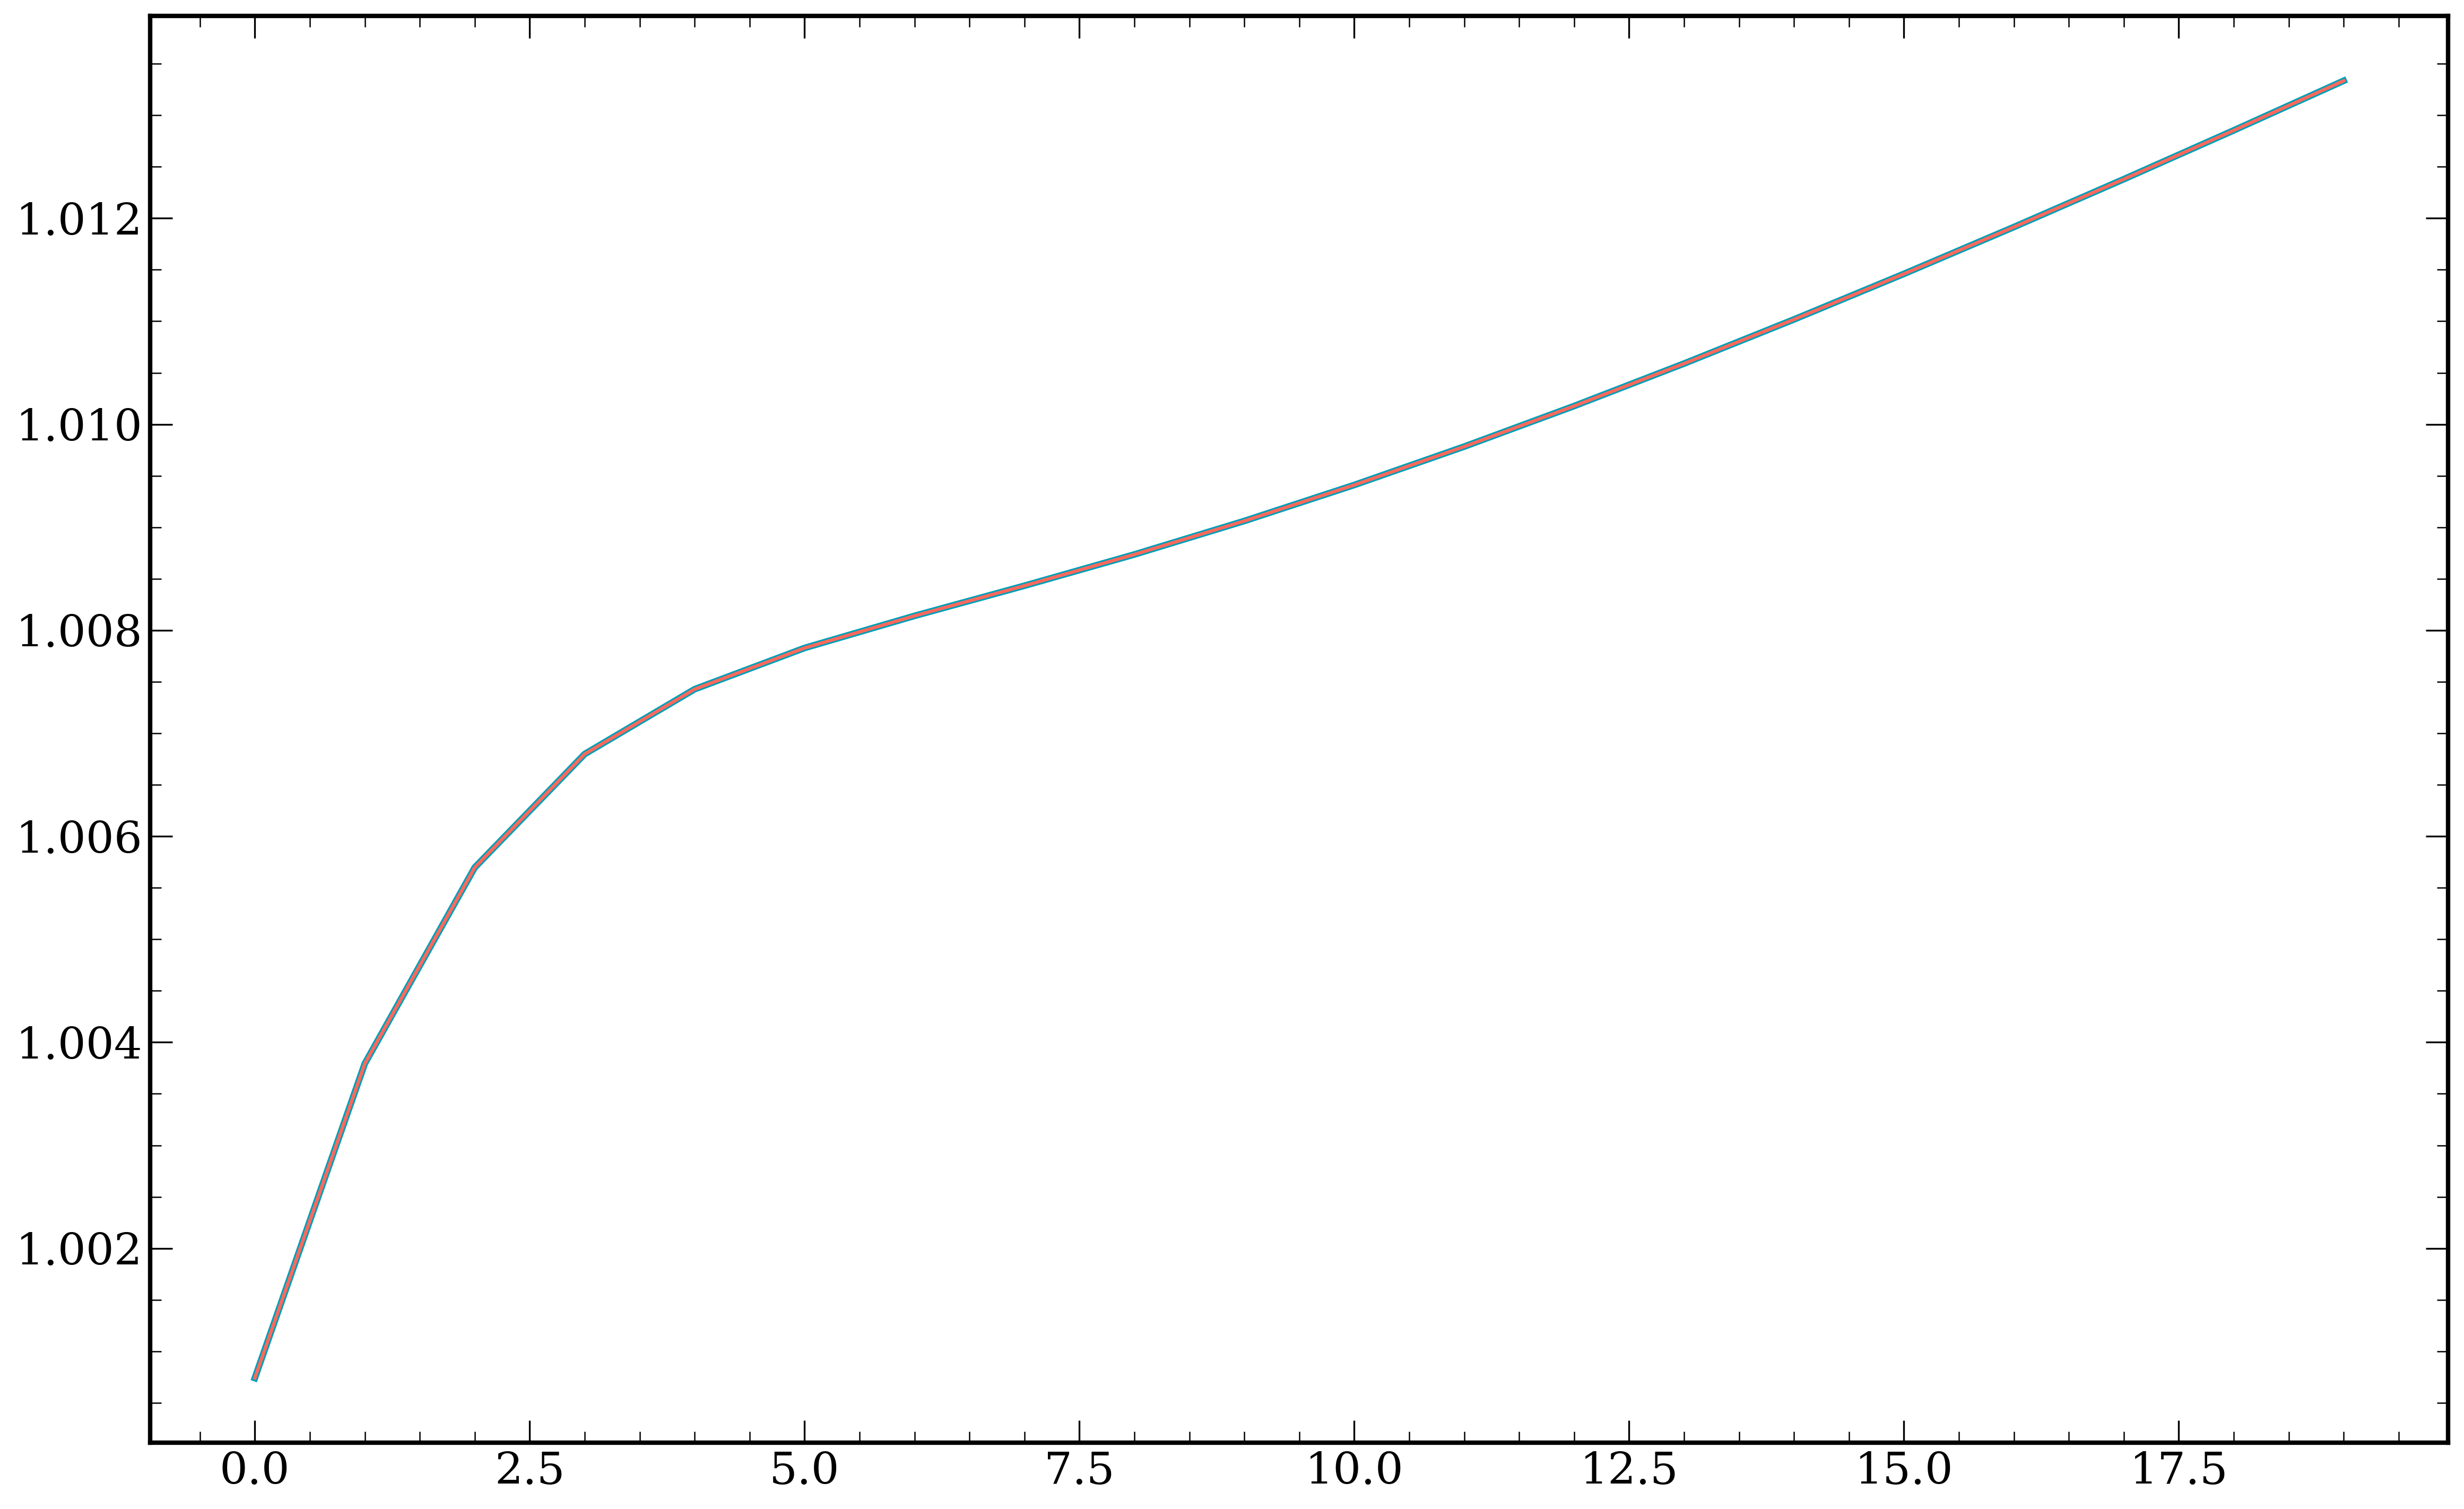

In [113]:
jax_rosseland_opacity = compute_rosseland_opacity(jax_total_opacity_linear[:,:,0,:], jax_temperatures, jax_wgauss, jax_frequency_bin_edges, True, jax_continuum_opacities)
rosseland_opacity = fs.compute_rosseland_opacities(line_opacities_grid_linear[:,:,0,:], temperatures, w_gauss, frequency_bin_edges, True, continuum_opacities_transpose)
plt.plot(jax_rosseland_opacity,linewidth=3)
plt.plot(rosseland_opacity)

%timeit compute_rosseland_opacity(jax_total_opacity_linear[:,:,0,:], jax_temperatures, jax_wgauss, jax_frequency_bin_edges, True, jax_continuum_opacities)
%timeit fs.compute_rosseland_opacities(line_opacities_grid_linear[:,:,0,:], temperatures, w_gauss, frequency_bin_edges, True, continuum_opacities_transpose)

In [115]:
def feautrier_rad_trans(border_freqs,
                        tau_approx_scat,
                        temperature,
                        mu,
                        w_gauss_mu,
                        w_gauss_ck,
                        photon_destruct_in,
                        surf_refl,
                        surf_emi,
                        I_star_0,
                        geom,
                        mu_star):
    
    # Lengths of arrays
    freq_len_bounded = border_freqs.shape[0] - 1
    struc_len = temperature.shape[0]
    N_mu = mu.shape[0]
    g_len = w_gauss_ck.shape[0]

    # Definitions
    I_plus_surface = jnp.zeros((N_mu,g_len,freq_len_bounded))
    I_minus = 0.0

    GCM_read = False
    iter_scat = 1000

    source = jnp.zeros((g_len,freq_len_bounded,struc_len))
    flux_old = jnp.zeros((freq_len_bounded))
    flux = jnp.zeros((freq_len_bounded))
    source_planet_scat_n = jnp.zeros((g_len,freq_len_bounded,struc_len))
    source_planet_scat_n1 = jnp.zeros((g_len,freq_len_bounded,struc_len))
    source_planet_scat_n2 = jnp.zeros((g_len,freq_len_bounded,struc_len))
    source_planet_scat_n3 = jnp.zeros((g_len,freq_len_bounded,struc_len))

    photon_destruct = photon_destruct_in

    # DO THE STELLAR ATTENUATION CALCULATION
    J_star_ini = jnp.zeros((g_len,freq_len_bounded,struc_len))
    I_star_calc = jnp.zeros((g_len,N_mu,struc_len,freq_len_bounded))
    plancks = jnp.zeros((struc_len,freq_len_bounded))
    a = jnp.zeros((struc_len,N_mu))
    b = jnp.zeros((struc_len,N_mu))
    c= jnp.zeros((struc_len,N_mu))
    r= jnp.zeros(struc_len)
    I_J=jnp.zeros((struc_len,N_mu))
    I_H=jnp.zeros((struc_len,N_mu))
    J_bol = jnp.zeros(struc_len)

    lambda_loc = jnp.zeros((g_len,freq_len_bounded,struc_len))
    J_planet_scat = jnp.zeros((g_len,freq_len_bounded,struc_len))
    inv_del_tau_min = 1e10
    J_bol = J_bol.at[1].set(0) #jnp.zeros(struc_len)
    I_GCM = jnp.zeros((N_mu,freq_len_bounded))

    planck= jnp.zeros(struc_len)
    for i in range(freq_len_bounded):
        # Irradiation treatment
        # Dayside ave: multiply flux by 1/2.
        # Planet ave: multiply flux by 1/4
        for i_mu in range(N_mu):
            if  geom ==0:
                I_star_calc = I_star_calc.at[:,i_mu,:,i].set(0.5* jnp.abs(I_star_0[i])*jnp.exp(-tau_approx_scat[:,i,:]/mu[i_mu]))
                J_star_ini = J_star_ini.at[:,i,:].set(J_star_ini[:,i,:]+0.5*I_star_calc[:,i_mu,:,i]*w_gauss_mu[i_mu])
            elif geom ==1:
                I_star_calc = I_star_calc.at[:,i_mu,:,i].set(0.25* jnp.abs(I_star_0[i])*jnp.exp(-tau_approx_scat[:,i,:]/mu[i_mu]))
                J_star_ini = J_star_ini.at[:,i,:].set(J_star_ini[:,i,:]+0.5*I_star_calc[:,i_mu,:,i]*w_gauss_mu[i_mu])
            elif geom==2:
                J_star_ini = J_star_ini.at[:,i,:].set(jnp.abs(I_star_0[i]/4.*jnp.exp(-tau_approx_scat[:,i,:]/mu_star)))
            else:
                print('Invalid geometry')

    for i in range(freq_len_bounded):
        r = planck_f_lr(temperature,border_freqs[i],border_freqs[i+1])
        plancks = plancks.at[:, i].set(r)
    photon_destruct = jnp.where(photon_destruct_in<1e-10,1e-10,photon_destruct)
    for i_iter_scat in range(iter_scat):
        J_bol = jnp.zeros(struc_len)
        I_GCM = I_GCM.at[:,i].multiply(0.0)

        flux_old = flux
        for i in range(freq_len_bounded):
            r = plancks[:, i]
            planck = plancks[:, i]
            for l in range(g_len):
                if i_iter_scat == 0:
                    source = source.at[l,i,:].set(photon_destruct[l,i,:]*r +  (1.0-photon_destruct[l,i,:])*J_star_ini[l,i,:])
                else:
                    r = source[l,i,:]
                for j in range(N_mu):
                    # Own boundary treatment
                    f1 = mu[j]/(tau_approx_scat[l,i,1]-tau_approx_scat[l,i,0])

                    # own test against instability
                    f1 = lax.select(f1 > inv_del_tau_min, inv_del_tau_min, f1)
                    f1 = lax.select(f1 != f1, inv_del_tau_min, f1)

                    b= b.at[0].set(1.0 + 2.0 * f1 * (1.0 + f1))
                    c = c.at[0].set(-2.0*f1**2.0)
                    a = a.at[0].set(0.0)

                    # Calculate the local approximate lambda iterator
                    lambda_loc = lambda_loc.at[l,i,1].add(w_gauss_mu[j]/(1.0 + 2.0 * f1 * (1.0 + f1)))

                    for k in range(1,struc_len-1):
                        f1 = 2.0*mu[j]/(tau_approx_scat[l,i,k+1]-tau_approx_scat[l,i,k-1])
                        f2 = mu[j]/(tau_approx_scat[l,i,k+1]-tau_approx_scat[l,i,k])
                        f3 = mu[j]/(tau_approx_scat[l,i,k]-tau_approx_scat[l,i,k-1])
                        
                        # own test against instability
                        f1 = lax.select(f1 > 0.5*inv_del_tau_min, 0.5*inv_del_tau_min, f1)
                        f1 = lax.select(f1 != f1, 0.5*inv_del_tau_min, f1)
                        f2 = lax.select(f2 > inv_del_tau_min, inv_del_tau_min, f2)
                        f2 = lax.select(f2 != f2, inv_del_tau_min, f2)
                        f3 = lax.select(f3 > inv_del_tau_min, inv_del_tau_min, f3)
                        f3 = lax.select(f3 != f3, inv_del_tau_min, f3)

                        b = b.at[k].set(1.0 + f1*(f2+f3))
                        c = c.at[k].set(-f1*f2)
                        a = a.at[k].set(-f1*f3)

                        # Calculate the local approximate lambda iterator
                        lambda_loc = lambda_loc.at[l,i,k].add(w_gauss_mu[j]/(1.0+f1*(f2+f3)))
                    # Own boundary treatment
                    f1 = mu[j]/(tau_approx_scat[l,i,struc_len]-tau_approx_scat[l,i,struc_len-1])

                    f1 = lax.select(f1 > inv_del_tau_min, inv_del_tau_min, f1)
                    f1 = lax.select(f1 != f1, inv_del_tau_min, f1)

                    # TEST PAUL SCAT
                    a = a.at[struc_len].set(0.0)
                    b = b.at[struc_len].set(1.0)
                    c = c.at[struc_len].set(0.0)

                    # r(struc_len) = I_J(struc_len) = 0.5[I_plus + I_minus]
                    # where I_plus is the light that goes downwards and
                    # I_minus is the light that goes upwards.
                    ################## ALWAYS NEEDED ##################
                    I_plus = I_plus_surface[j, l, i]

                    ############### EMISSION ONLY TERM ################
                    I_minus = surf_emi[i]*planck[struc_len] \
                        + surf_refl[i] * 2.0 * jnp.sum(I_plus_surface[:, l, i] * mu * w_gauss_mu)
                    ############### SURFACE SCATTERING ################
                    # ----> of the emitted/scattered atmospheric light
                    # + surf_refl(i) * SUM(I_plus_surface(:, l, i) * w_gauss_mu) # OLD PRE 091220
                    # ----> of the direct stellar beam (depends on geometry)

                    if  geom != 2:
                        I_minus = I_minus + surf_refl[i] \
                            * 2.0 * jnp.sum(I_star_calc[l,:, struc_len, i] * mu * w_gauss_mu)
                    else:
                        I_minus = I_minus + surf_refl[i] *J_star_ini[l,i,struc_len] * 4.0 * mu_star
                    #sum to get I_J
                    r = r.at[struc_len].set(0.5*(I_plus + I_minus))

                    # Calculate the local approximate lambda iterator
                    lambda_loc = lambda_loc.at[l,i,struc_len].add(w_gauss_mu[j]/(1.0 + 2.0*f1**2.0))

                    I_J = I_J.at[:,j].set(tridag_own(a[:,j],b[:,j],c[:,j],r))
                    I_H = I_H.at[1,j].set(-I_J[0,j])

                    for k in range(1,struc_len-1):
                        f1 = mu[j]/(tau_approx_scat[l,i,k+1]-tau_approx_scat[l,i,k])
                        f2 = mu[j]/(tau_approx_scat[l,i,k]-tau_approx_scat[l,i,k-1])

                        f1 = lax.select(f1 > inv_del_tau_min, inv_del_tau_min, f1)
                        f2 = lax.select(f2 > inv_del_tau_min, inv_del_tau_min, f2)
                        deriv1 = f1*(I_J[k+1,j]-I_J[k,j])
                        deriv2 = f2*(I_J[k,j]-I_J[k-1,j])
                        I_H = I_H.at[k,j].set(-(deriv1+deriv2)/2.0)

                        if (k == struc_len - 1):
                            I_plus_surface = I_plus_surface.at[j, l, i].set(I_J[struc_len,j]  - deriv1)

                    I_H = I_H.at[struc_len,j].set(0.0)
                J_bol_g = jnp.zeros(struc_len)

                for j in range(N_mu):
                    J_bol_g = J_bol_g + I_J[:,j] * w_gauss_mu[j]
                    flux= flux.at[i].add(-I_H[1,j]*mu[j]* 4.0 *jnp.pi * w_gauss_ck[l] * w_gauss_mu[j])

                # Save angle-dependent surface flux
                if GCM_read:
                    for j in range(N_mu):
                        I_GCM = I_GCM.at[j,i].add( - 2.0*I_H[1,j]*w_gauss_ck[l])
                J_planet_scat = J_planet_scat.at[l,i,:].set(J_bol_g)
        
        photon_destruct = jnp.where(photon_destruct < 1e-10, 1e-10, photon_destruct)
        for i in range(freq_len_bounded):
            r = planck_f_lr(temperature[1:struc_len],border_freqs[i],border_freqs[i+1])
            for l in range(g_len):
                source = source.at[l,i,:].set((photon_destruct[l,i,:]*r+(1.0-photon_destruct[l,i,:])* \
                    (J_star_ini[l,i,:]+J_planet_scat[l,i,:]-lambda_loc[l,i,:]*source[l,i,:])) / \
                    (1.0-(1.0-photon_destruct[l,i,:])*lambda_loc[l,i,:]))

        source_planet_scat_n3 = source_planet_scat_n2
        source_planet_scat_n2 = source_planet_scat_n1
        source_planet_scat_n1 = source_planet_scat_n
        source_planet_scat_n  = source

        if i_iter_scat%4 == 0:
            #write(*,*) 'Ng acceleration#' 
            # CHECK CHECK CHECK
            source = NG_source_approx(source_planet_scat_n,
                                      source_planet_scat_n1,
                                      source_planet_scat_n2,
                                      source_planet_scat_n3,)

        conv_val = jnp.max(jnp.abs((flux-flux_old)/flux))
        if ((conv_val < 1e-3) and (i_iter_scat > 9)):
            break

    # Calculate the contribution function.
    # Copied from flux_ck, here using "source" as the source function
    # (before it was the Planck function).
    struct_shape = (freq_len_bounded,temperature.shape[0])
    contr_em = jnp.zeros(struct_shape)

    # Let's ignore the contribution function for now.
    if False:
        for i_mu in range(mu.shape[0]):
            # Transmissions for a given incidence angle
            transm_mu = jnp.exp(-transmission/mu[i_mu])

            # Flux contribution from given mu-angle

            #mean_transm = np.zeros((struct_shape[0],transmission.shape[2],struct_shape[1])
            mean_transm = jnp.sum(transm_mu* w_gauss[:, None, None, None], axis=0)
            transm_all = jnp.prod(mean_transm, axis=1)
            r = jnp.sum(source*w_gauss_ck[:,None,None,None],axis = 0)
            #r = planck_f(temperature,frequency)
            # Do the actual radiative transport
            contr_em = contr_em.at[:,:-1].add((r[:,:-1]+r[:,1:])*(transm_all[:,0:-1]-transm_all[:,1:]) *\
                                            mu[i_mu]*w_gauss_mu[i_mu])     
            contr_em = contr_em.at[:,-1].add(2.0*r[:,struct_shape[1]] * transm_all[:,struct_shape[1]] *\
                                            mu[i_mu]*w_gauss_mu[i_mu])

            # angle integ, factor 1/2 needed for flux calc. from upward pointing intensity
        #Normalization
        contr_em = contr_em.T
        contr_em = jnp.divide(contr_em,jnp.sum(contr_em,axis=0))
    return source, contr_em
py_feautrier_rad_trans = jit(feautrier_rad_trans, static_argnames=('geom'))

@jit
def planck_f_lr(T,nul,nur):
    # calculate planck function between two frequencies
    B_nu = 0.0
    # Take mean using Boole's method
    nu_large = jnp.maximum(nul,nur)
    nu_small = jnp.minimum(nul,nur)
    nu1 = nu_small
    nu2 = nu_small+1.0*(nu_large-nu_small)/4.0
    nu3 = nu_small+2.0*(nu_large-nu_small)/4.0
    nu4 = nu_small+3.0*(nu_large-nu_small)/4.0
    nu5 = nu_large
    diff_nu = nu2-nu1
    B_nu = B_nu + 1.0/90.0*( \
        7.0* 2.0*cst.h*nu1**3.0/cst.c**2.0/(jnp.exp(cst.h*nu1/(cst.kB*T))-1.0) +\
        32.0*2.0*cst.h*nu2**3.0/cst.c**2.0/(jnp.exp(cst.h*nu2/(cst.kB*T))-1.0) +\
        12.0*2.0*cst.h*nu3**3.0/cst.c**2.0/(jnp.exp(cst.h*nu3/(cst.kB*T))-1.0) +\
        32.0*2.0*cst.h*nu4**3.0/cst.c**2.0/(jnp.exp(cst.h*nu4/(cst.kB*T))-1.0) +\
        7.0* 2.0*cst.h*nu5**3.0/cst.c**2.0/(jnp.exp(cst.h*nu5/(cst.kB*T))-1.0))
    return B_nu

@jit
def NG_source_approx(source_n,source_n1,source_n2,source_n3):
    N_g, freq_len_p_1,struc_len = source_n.shape
    source_buff = jnp.zeros((N_g,freq_len_p_1-1,struc_len))
    for i_freq in range(freq_len_p_1-1):
        for i_ng in range(N_g):
            tn = source_n[i_ng,i_freq,1:struc_len]
            tn1 = source_n1[i_ng,i_freq,1:struc_len]
            tn2 = source_n2[i_ng,i_freq,1:struc_len]
            tn3 = source_n3[i_ng,i_freq,1:struc_len]

            Q1 = tn - 2.0*tn1 + tn2
            Q2 = tn - tn1 - tn2 + tn3
            Q3 = tn - tn1

            # test
            Q1[1] = 0.0
            Q2[1] = 0.0
            Q3[1] = 0.0

            A1 = jnp.sum(Q1*Q1)
            A2 = jnp.sum(Q2*Q1)
            B1 = jnp.sum(Q1*Q2)
            B2 = jnp.sum(Q2*Q2)
            C1 = jnp.sum(Q1*Q3)
            C2 = jnp.sum(Q2*Q3)

            if ((jnp.abs(A1) >= 1e-250) and \
                (jnp.abs(A2) >=1e-250) and \
                (jnp.abs(B1) >=1e-250) and \
                (jnp.abs(B2) >=1e-250) and \
                (jnp.abs(C1) >=1e-250) and \
                (jnp.abs(C2) >=1e-250)):

                a = (C1*B2-C2*B1)/(A1*B2-A2*B1)
                b = (C2*A1-C1*A2)/(A1*B2-A2*B1)

                temp_buff = (1.0-a-b)*tn + a*tn1 + b*tn2
                temp_buff = jnp.where(temp_buff <= 0.0, 0.0, temp_buff)
                source_buff = source_buff.at[i_ng,i_freq,1:struc_len].set(temp_buff)
            else:
                source_buff = source_buff.at[i_ng,i_freq,1:struc_len].set(source[i_ng,i_freq,1:struc_len])
    source = source_buff
    return source

## Tri Diagonal Matrix Algorithm(a.k.a Thomas algorithm) solver
# https://gist.github.com/cbellei/8ab3ab8551b8dfc8b081c518ccd9ada9
@jit 
def tridag_own(a, b, c, d):
    '''
    TDMA solver, a b c d can be NumPy array type or Python list type.
    refer to http://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm
    and to http://www.cfd-online.com/Wiki/Tridiagonal_matrix_algorithm_-_TDMA_(Thomas_algorithm)
    '''
    nf = len(d) # number of equations
    ac, bc, cc, dc = map(jnp.array, (a, b, c, d)) # copy arrays
    for it in range(1, nf):
        mc = ac[it]/bc[it-1]
        bc = bc.at[it].add(- mc*cc[it-1])
        dc = dc.at[it].add(- mc*dc[it-1])
    xc = bc
    xc = xc.at[-1].set(dc[-1]/bc[-1])

    for il in range(nf-2, -1, -1):
        xc = xc.at[il].set((dc[il]-cc[il]*xc[il+1])/bc[il])
    return xc
    


In [2]:
from petitRADTRANS.retrieval.parameter import Parameter
from petitRADTRANS.retrieval.models import guillot_emission
import copy as cp

parameters = {}
parameters['log_g'] = Parameter('log_g', False, value = 4.00)
parameters['D_pl'] = Parameter('D_pl', False, value = 20.0*cst.pc)
parameters['planet_radius'] = Parameter('planet_radius', False, value = 1.0*cst.r_jup)
parameters['T_int'] = Parameter('T_int', False, value = 500)
parameters['T_equ'] = Parameter('T_equ', False, value = 100)
parameters['gamma'] = Parameter('gamma', False, value = 0.1)
parameters['log_kappa_IR'] = Parameter('log_kappa_IR', False, value = 0.1)

parameters['H2O__POKAZATEL'] = Parameter('H2O__POKAZATEL', False, value = -1.5)
parameters['CO-NatAbund__HITEMP'] = Parameter('CO_all_iso_HITEMP', False, value = -1.3)

parameters['pressure_simple'] = Parameter('pressure_simple', False, value = 100)
parameters['pressure_scaling'] = Parameter('pressure_scaling', False, value = 10)
parameters['pressure_width'] = Parameter('pressure_width', False, value = 3)
species = ['H2O__POKAZATEL', 'CO-NatAbund__HITEMP']
rayleigh_species = ['H2', 'He']
continuum_opacities = ['H2-H2', 'H2-He']
#cloud_species = ["Fe(c)_cd","MgSiO3(c)_cd"]
cloud_species = []
pressures = np.logspace(-6,3,80)

atmosphere = Radtrans(pressures=pressures,
                      line_species = cp.copy(species),
                      rayleigh_species = cp.copy(rayleigh_species),
                      gas_continuum_contributors = cp.copy(continuum_opacities),
                      cloud_species = cp.copy(cloud_species),
                      line_opacity_mode='c-k',
                      wavelength_boundaries = [1.0,1.5],
                      scattering_in_emission = False)


/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/_input_data_loader.py:275: UserWarning: file '.DS_Store' lack spectral information (resolution: , range: )
  warnings.warn(f"file '{file}' lack spectral information "


Loading Radtrans opacities...
 Loading line opacities of species 'H2O__POKAZATEL' from file '/Users/nasedkin/testing/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R1000_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO-NatAbund__HITEMP' from file '/Users/nasedkin/testing/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R1000_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Successfully loaded all line opacities
 Loading CIA opacities for H2-H2 from file '/Users/nasedkin/testing/input_data/opacities/continuum/collision_induced_absorptions/H2--H2/H2--H2-NatAbund/H2--H2-NatAbund__BoRi.R831_0.6-250mu.ciatable.petitRADTRANS.h5'... Done.
 Loading CIA opacities for H2-He from file '/Users/nasedkin/testing/input_data/opacities/continuum/collision_induced_absorptions/H2--He/H2--He-NatAbund/H2--He-NatAbund__BoRi.DeltaWavenumber2_0.5-500mu.ciatable.petitRADTRANS.h5'... Done.
 Successfully loaded all CIA opacities
Suc

In [7]:
flux = guillot_emission(atmosphere,parameters,amr=False,pt_plot_mode=False)

Fortran optical depths: 0.006196022033691406
JAX optical depths: 0.024824857711791992
(16, 406, 2, 80) (16, 406, 2, 80)
[[[[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  ...

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]]


 [[[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  ...

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]

  [[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  1. ...  1.  1.  1.]]]


 [[[nan  1.  1. ...  1.  1.  1.]
   [nan  1.  

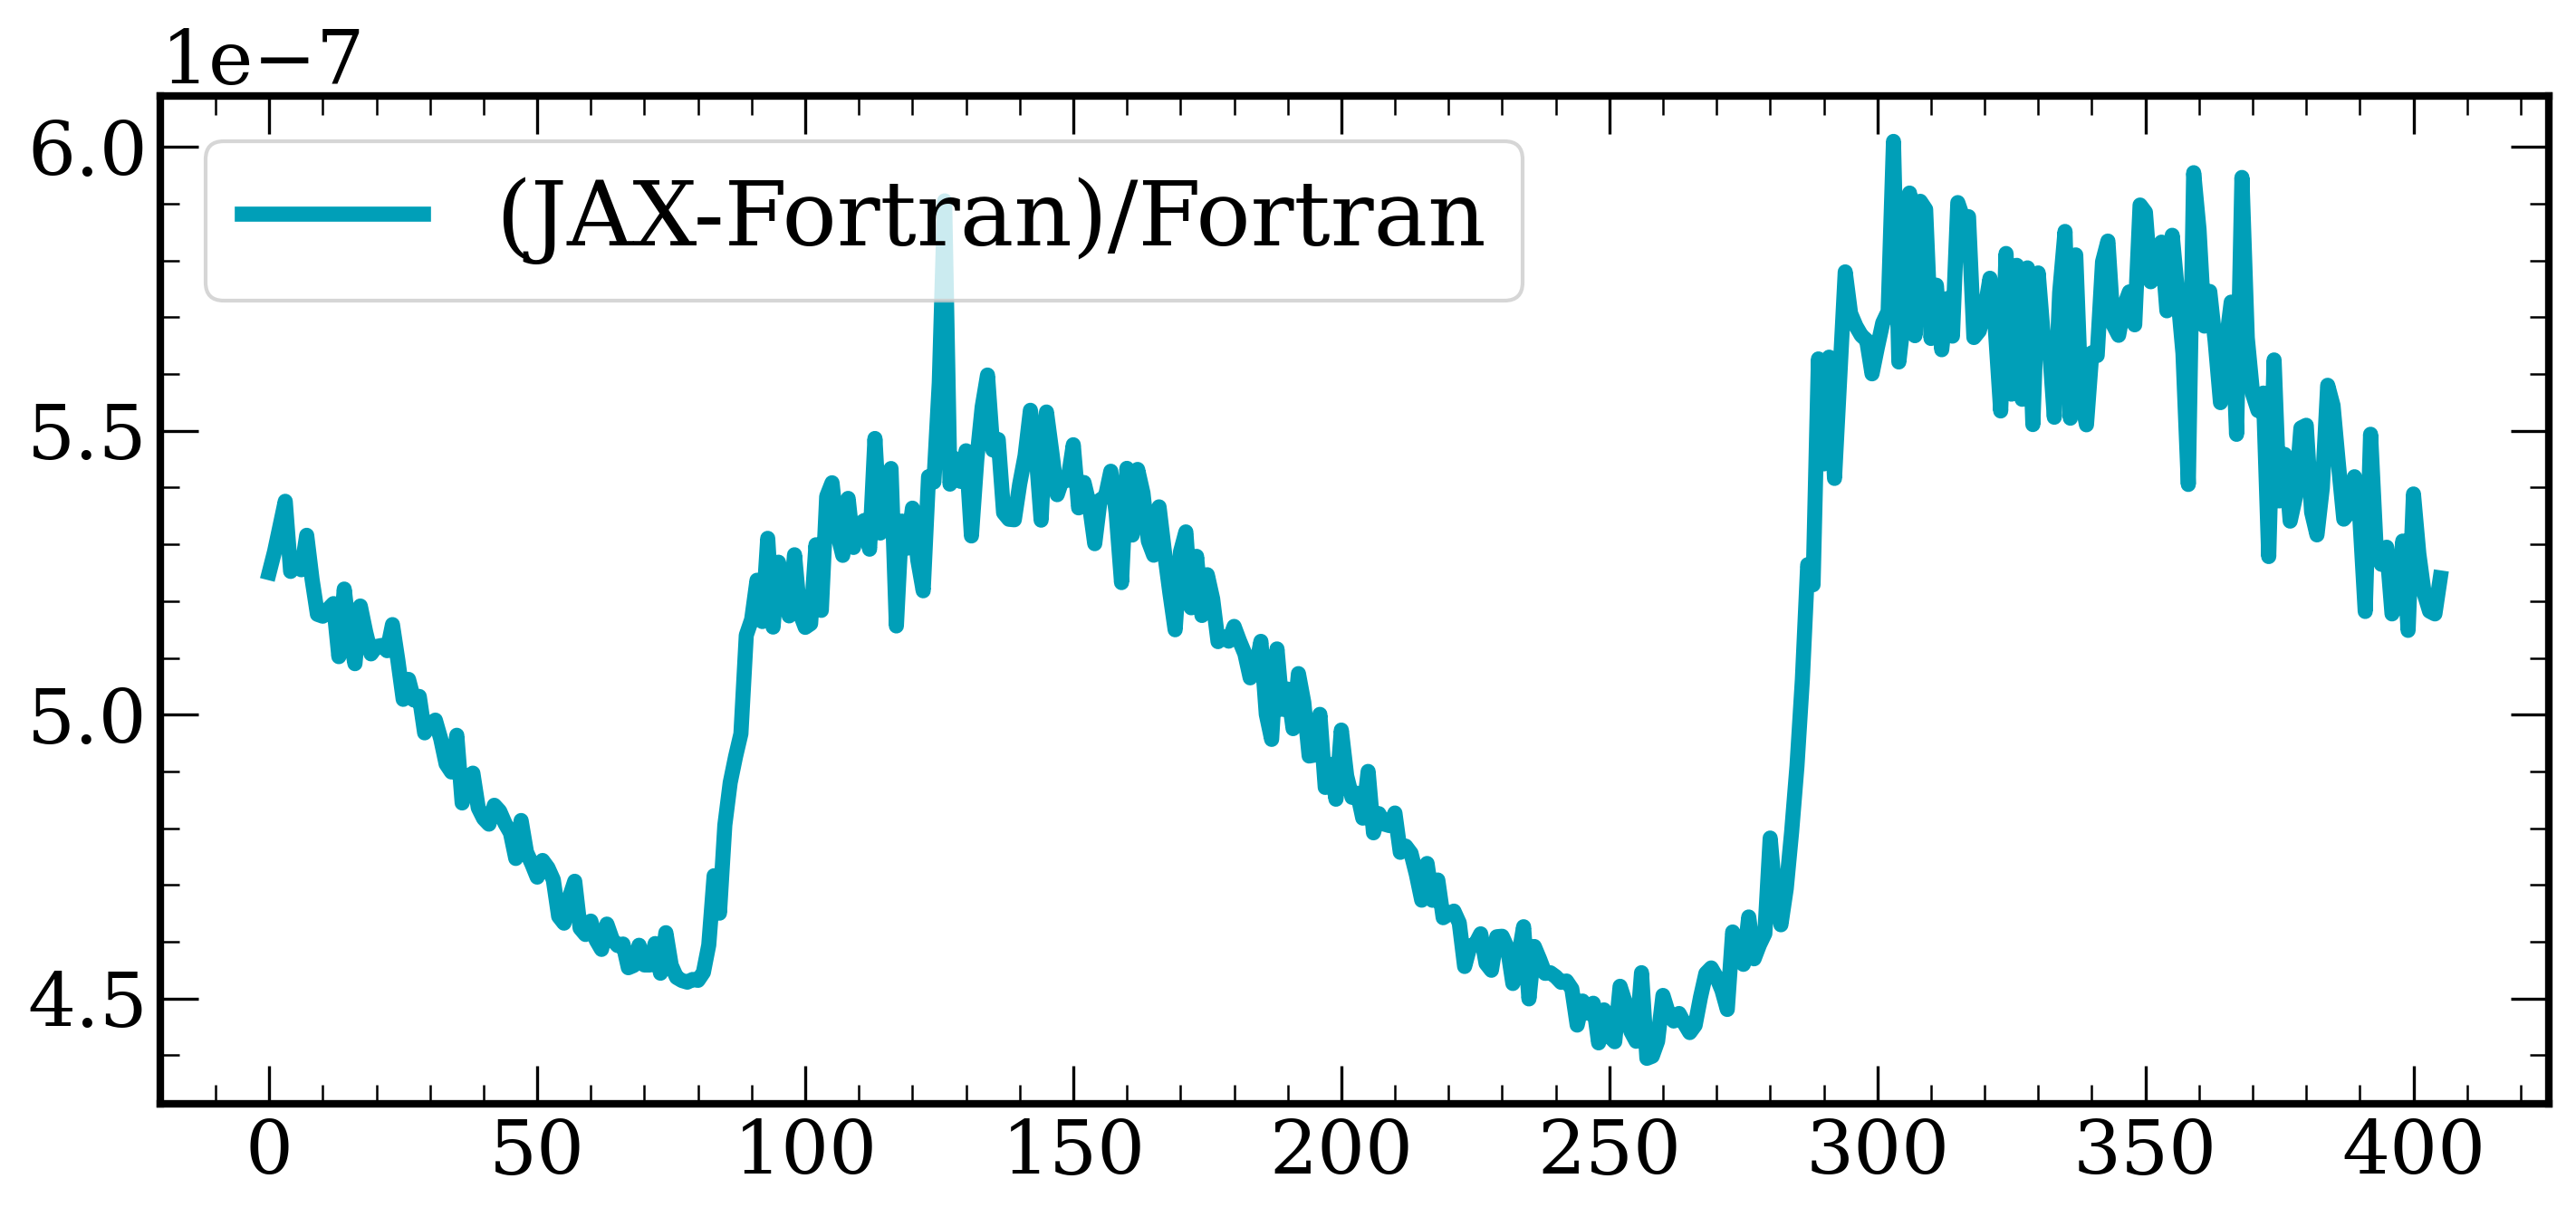

In [16]:
import matplotlib.pyplot as plt
jax_spec = np.load("jax_flux.npy")
spec = np.load("fortran_flux.npy")
fig,ax = plt.subplots(figsize = (10,5))
ax.plot((jax_spec-spec)/spec,linewidth=4,label = "(JAX-Fortran)/Fortran")
#ax.plot(spec,label = "Fortran, 0.0209s")
ax.legend()
plt.savefig("/Users/nasedkin/testing/pRTPlots/JaxFortranCalcckResiduals.pdf")

In [3]:
@jit
def tridag_wrapped(a,b,c,d):

    out = lax.map(tridag_own,)

@jit 
def tridag_own(a, b, c, d):
    '''
    TDMA solver, a b c d can be NumPy array type or Python list type.
    refer to http://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm
    and to http://www.cfd-online.com/Wiki/Tridiagonal_matrix_algorithm_-_TDMA_(Thomas_algorithm)
    '''
    nf = len(d) # number of equations
    ac,bc,cc,dc = lax.fori_loop(1,nf,internal_tridag,(a,b,c,d))     
    xc = bc
    xc = xc.at[-1].set(dc[-1]/bc[-1])
    xc = jnp.flip(xc)
    bc = jnp.flip(bc)
    cc = jnp.flip(cc)
    dc = jnp.flip(dc)
    xc,bc,cc,dc = lax.fori_loop(0,nf-1,internal_tridag_reverse,(xc,bc,cc,dc))
    return jnp.flip(xc)

@jit
def internal_tridag_reverse(il,val):
    xc,bc,cc,dc = val
    xc = xc.at[il].set((dc[il]-cc[il]*xc[il-1])/bc[il])
    return (xc,bc,cc,dc)

@jit
def internal_tridag(it,val):
    ac,bc,cc,dc = val
    mc = ac[it]/bc[it-1]
    bc = bc.at[it].add(- mc*cc[it-1])
    dc = dc.at[it].add(- mc*dc[it-1])
    return (ac,bc,cc,dc)

@jit
def solve_tridiag(ts, tus, tls, b):
  """Solve Tx=b where T is tridiagonal, w/diagonal ts, upper tus, lower tls."""
  prepend_zero = lambda x: jnp.append(jnp.zeros(1), x[:-1])
  fwd1 = lambda tu_, x: x[1] / (x[0] - x[2] * tu_)
  fwd2 = lambda b_, x: (x[0] - x[3] * b_) / (x[1] - x[3] * x[2])
  bwd1 = lambda x_, x: x[0] - x[1] * x_
  double = lambda f, args: (f(*args), f(*args))

  # forward pass
  _, tu_ = lax.scan(
      lambda tu_, x: double(fwd1, (tu_, x)),
      tus[0] / ts[0],
      (ts, tus, prepend_zero(tls)),
      unroll=32)
  _, b_ = lax.scan(
      lambda b_, x: double(fwd2, (b_, x)),
      b[0] / ts[0],
      (b, ts, prepend_zero(tu_), prepend_zero(tls)),
      unroll=32)

  # backsubstitution
  _, x_ = lax.scan(
      lambda x_, x: double(bwd1, (x_, x)), 0, (b_[::-1], tu_[::-1]), unroll=32)
  return x_[::-1]

'''@jit
def tridag_own_new(a,b,c,res):
    # I/O
    length = a.shape[0]
    # Internal variables
    buffer_vector = jnp.zeros(length)
    # Begin inversion
    buffer_scalar = b[0]

    solution = jnp.zeros(length)
    solution = solution.at[0].set(res[0] / buffer_scalar)

    for ind in range(1,length):
        buffer_vector = buffer_vector.at[ind].set(c[ind-1]/buffer_scalar)
        buffer_scalar = b[ind] - a[ind] * buffer_vector[ind]

        solution = solution.at[ind].set(res[ind] / buffer_scalar)
        #solution_pre = solution(ind - 1) / buffer_scalar
        
        #solution = solution.at[ind].set((res[ind] - \
        #    a[ind]*solution[ind-1])/buffer_scalar)

    for ind in range(length-1, 0, -1):
        solution = solution.at[ind].set(solution[ind] - buffer_vector[ind + 1] * solution[ind + 1])
        #solution = solution.at[ind].divide(- buffer_vector[ind+1] * solution[ind + 1])
    return solution'''


'@jit\ndef tridag_own_new(a,b,c,res):\n    # I/O\n    length = a.shape[0]\n    # Internal variables\n    buffer_vector = jnp.zeros(length)\n    # Begin inversion\n    buffer_scalar = b[0]\n\n    solution = jnp.zeros(length)\n    solution = solution.at[0].set(res[0] / buffer_scalar)\n\n    for ind in range(1,length):\n        buffer_vector = buffer_vector.at[ind].set(c[ind-1]/buffer_scalar)\n        buffer_scalar = b[ind] - a[ind] * buffer_vector[ind]\n\n        solution = solution.at[ind].set(res[ind] / buffer_scalar)\n        #solution_pre = solution(ind - 1) / buffer_scalar\n        \n        #solution = solution.at[ind].set((res[ind] -         #    a[ind]*solution[ind-1])/buffer_scalar)\n\n    for ind in range(length-1, 0, -1):\n        solution = solution.at[ind].set(solution[ind] - buffer_vector[ind + 1] * solution[ind + 1])\n        #solution = solution.at[ind].divide(- buffer_vector[ind+1] * solution[ind + 1])\n    return solution'

In [4]:
from scipy.linalg import solve_banded
#from jax.scipy import sparse
from scipy import sparse

N_frequencies_for_tridiag = 80
ja = jnp.ones(N_frequencies_for_tridiag)
jb = jnp.ones(N_frequencies_for_tridiag)*2
jc = jnp.ones(N_frequencies_for_tridiag)*3
jd = jnp.ones(N_frequencies_for_tridiag)*2

a = np.ones(N_frequencies_for_tridiag)
b = np.ones(N_frequencies_for_tridiag)*2
c = np.ones(N_frequencies_for_tridiag)*3
d = np.ones(N_frequencies_for_tridiag)*2

a[0] = 0
c[-1] = 0

diag = jnp.diag(jd)
diags = [-1,0,1]                  # which diagonal each vector goes into
M = sparse.diags([ja,jb,jc],diags, shape = (80,80),format='csc') # create the matrix
def build_ab(a,b,c):
    ab = jnp.array([ja,jb,jc])
    return ab

banded = build_ab(a,b,c)
#print(banded.shape)
@jit
def fast_fn(a,b,c,d):
    return lax.linalg.tridiagonal_solve(ja,jb,jc,diag)

def scipy_tridag(A,r):
    return solve_banded((1,1),A,r)

%timeit scipy_tridag(banded,d)
%timeit tridag_own(ja,jb,jc,jd)
%timeit math.solve_tridiagonal_system(a,b,c,d)
%timeit fast_fn(ja,jb,jc,jd)

print(tridag_own(ja,jb,jc,jd)/math.solve_tridiagonal_system(a,b,c,d))
# Testing for 80 frequency points
# scipy_tridag 24.6 µs ± 3.75 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
# tridag_own 12.6 µs ± 1.12 µs per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
# tridag_own_new 27.9 µs ± 3.92 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
# math.solve_tridiagonal_system1.45 µs ± 32.6 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)
# fast_fn 224 µs ± 59.1 µs per loop (mean ± std. dev. of 7 runs, 1 loop each)


6.32 μs ± 86.9 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
10.3 μs ± 193 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
595 ns ± 17.3 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)
The slowest run took 6.54 times longer than the fastest. This could mean that an intermediate result is being cached.
6.52 μs ± 6.17 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)
[-5.53943705e-19 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00
 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00
 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00
 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00
 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00
 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00
 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00
 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00
 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00 -5.00000000e+00


In [15]:
a = jnp.ones((10,20))*2
b = jnp.ones((10,20,3))
b = b.at[:,:,:].set(a[:,:,None])
#print(b)


def myFunc():
    return 5
def falseFunc():
    return 0
a = 3
a = lax.cond(False,lambda: myFunc(), lambda: 0)
#print(a)

In [1]:
import tensorflow_probability.substrates.jax as tfp
from jax import random, numpy as jnp

from jaxns import DefaultNestedSampler
from jaxns import Model
from jaxns import Prior

tfpd = tfp.distributions
ndims = 2


INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': 
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/nasedkin/anaconda3/envs/prt3python312/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file), '/usr/local/lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache)


<tfp.distributions.Uniform 'Uniform' batch_shape=[2] event_shape=[] dtype=float32>

In [3]:
x = tfpd.Uniform(low=jnp.zeros(ndims), high= 30 * jnp.ones(ndims))
print(x)

tfp.distributions.Uniform("Uniform", batch_shape=[2], event_shape=[], dtype=float32)


In [8]:
def test(x):
    y = yield Prior(x,name="test")
    return y
y=test(x)
print(y+0)

TypeError: unsupported operand type(s) for +: 'generator' and 'int'

In [29]:
from scipy.interpolate import interp1d
import numpy as np
import sys
import petitRADTRANS.physical_constants as cst

In [54]:

prtdir="petitRADTRANS/retrieval/"
weight = np.load(f"{prtdir}collisionweight.npy")
#combined_mass_fractions = np.load(f"{prtdir}combined_mass_fractions.npy")
#mean_molar_masses= np.load(f"{prtdir}mean_molar_masses.npy")
temperatures = np.load(f"{prtdir}temperatures.npy")
alpha = np.load(f"{prtdir}collisionalpha.npy")
frequencies = np.load(f"{prtdir}frequencies.npy")
collisiontemperature = np.load(f"{prtdir}collisiontemperature.npy")
collisionlambda = np.load(f"{prtdir}collisionlambda.npy")
pressures = np.logspace(-6,3,100)*1e6
#cia_opacities = np.load("cia_opacities")

#factor = combined_mass_fractions / weight \
#            * mean_molar_masses / cst.amu / (cst.L0 ** 2) * pressures / cst.kB / temperatures

log10_alpha = np.log10(alpha)
print(collisiontemperature.shape)
#if collisiontemperature.shape[0] > 1:
# Interpolation on temperatures for each wave
# length point

print(collisiontemperature.shape,log10_alpha.shape,temperatures.shape)
interpolating_function = interp1d(
    x=collisiontemperature,
    y=log10_alpha,
    kind='linear',
    bounds_error=False,
    fill_value=(log10_alpha[:, 0], log10_alpha[:, -1]), axis=1
)

cia_opacities = np.exp(interpolating_function(temperatures) * np.log(10))


cia_npinterp_opacities = np.zeros((log10_alpha.shape[0],temperatures.shape[0]))
for i,a in enumerate(log10_alpha):
    cia_npinterp_opacities[i] =  np.interp(temperatures, collisiontemperature, a) 
cia_npinterp_opacities = np.exp(cia_npinterp_opacities* np.log(10))
print("CIA1:",cia_opacities.shape)
print(cia_opacities)
print(cia_opacities/cia_npinterp_opacities)




(48,)
(48,) (10000, 48) (100,)
CIA1: (10000, 100)
[[4.78814998e-14 4.78814998e-14 4.78814998e-14 ... 1.58089233e-13
  1.74011581e-13 1.92480205e-13]
 [4.80114360e-14 4.80114360e-14 4.80114360e-14 ... 1.58488686e-13
  1.74430326e-13 1.92919050e-13]
 [4.82568711e-14 4.82568711e-14 4.82568711e-14 ... 1.59058488e-13
  1.75081943e-13 1.93668224e-13]
 ...
 [3.71184489e-08 3.71184489e-08 3.71184489e-08 ... 2.98578516e-08
  2.94537122e-08 2.90347936e-08]
 [3.13507242e-08 3.13507242e-08 3.13507242e-08 ... 2.51477858e-08
  2.48053517e-08 2.44504249e-08]
 [2.60522136e-08 2.60522136e-08 2.60522136e-08 ... 2.08304276e-08
  2.05440793e-08 2.02473244e-08]]
[[1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 ...
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]]


In [49]:
print(collisionlambda.shape,cia_opacities.shape,frequencies.shape)
interpolating_function = interp1d(
    x=collisionlambda,
    y=cia_opacities,
    kind='linear',
    bounds_error=False,
    fill_value=sys.float_info.min,
    axis=0
)

cia_opacities = interpolating_function(cst.c / frequencies)
print("CIA2:",cia_opacities.shape)
print(cia_opacities)

cia_opacities[cia_opacities < sys.float_info.min] = 0

cia_npinterp_opacities_new = np.zeros((frequencies.shape[0],temperatures.shape[0]))
print(cia_npinterp_opacities_new.shape)
for i in range(temperatures.shape[0]):
    #test = np.interp(cst.c / frequencies, collisionlambda, cia_npinterp_opacities[:,i]) 
    #print(test.shape)
    cia_npinterp_opacities_new[:,i] =  np.interp(cst.c / frequencies, collisionlambda, cia_npinterp_opacities[:,i]) 
print(cia_opacities/cia_npinterp_opacities_new)

(10000,) (10000, 100) (274,)
CIA2: (274, 100)
[[1.23786311e-11 1.23786311e-11 1.23786311e-11 ... 8.64937790e-11
  9.61444075e-11 1.07451714e-10]
 [1.40061829e-11 1.40061829e-11 1.40061829e-11 ... 9.54435111e-11
  1.05997734e-10 1.18352385e-10]
 [1.58250072e-11 1.58250072e-11 1.58250072e-11 ... 1.05153887e-10
  1.16709028e-10 1.30226680e-10]
 ...
 [9.50317316e-07 9.50317316e-07 9.50317316e-07 ... 2.47366717e-06
  2.60805927e-06 2.75720527e-06]
 [8.08982481e-07 8.08982481e-07 8.08982481e-07 ... 2.26452759e-06
  2.39565664e-06 2.54168779e-06]
 [6.85292379e-07 6.85292379e-07 6.85292379e-07 ... 2.06552855e-06
  2.19283196e-06 2.33511521e-06]]
(274, 100)
[[1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 ...
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]]


In [55]:
import jax.numpy as jnp
import jax

cia_jnpinterp_opacities = jax.vmap(lambda alpha: jnp.interp(temperatures, collisiontemperature, alpha))(log10_alpha)
cia_jnpinterp_opacities = jnp.exp(cia_jnpinterp_opacities * jnp.log(10))
print(cia_jnpinterp_opacities/cia_npinterp_opacities)

[[1.0000013  1.0000013  1.0000013  ... 0.99999845 0.99999875 0.9999993 ]
 [0.9999997  0.9999997  0.9999997  ... 0.9999982  1.0000004  1.0000013 ]
 [1.000001   1.000001   1.000001   ... 1.0000011  0.9999985  1.0000011 ]
 ...
 [0.9999998  0.9999998  0.9999998  ... 0.9999995  0.9999994  1.0000002 ]
 [1.         1.         1.         ... 0.9999989  0.99999934 0.9999993 ]
 [0.9999997  0.9999997  0.9999997  ... 0.9999996  1.         0.9999989 ]]


In [2]:
import jax.numpy as jnp
from jax import config
config.update("jax_enable_x64", True)
from jax import jit,vmap,lax

import petitRADTRANS.physical_constants as cst

@jit
def H2_rayleigh(wavelengths_angstroem, mass_fractions):
    """Calculates H2 Rayleigh scattering opacities (optimized)."""

    # Constants hoisted out of the calculation loop
    abundance_threshold = 1e-60
    c1 = 8.14e-13 / 1.66053892e-24 * 0.5
    c2 = 1.28e-6 / 1.66053892e-24 * 0.5
    c3 = 1.61 / 1.66053892e-24 * 0.5

    # Precompute inverse powers to avoid redundant calculations
    inv_wavelengths2 = 1 / wavelengths_angstroem**2
    inv_wavelengths4 = inv_wavelengths2**2
    inv_wavelengths6 = inv_wavelengths4 * inv_wavelengths2
    inv_wavelengths8 = inv_wavelengths6 * inv_wavelengths2

    # Compute the factor vectorized
    factor = c1 * inv_wavelengths4 + c2 * inv_wavelengths6 + c3 * inv_wavelengths8

    # Compute opacities, avoiding unnecessary zeros
    rayleigh_scattering_opacities = factor[:, None] * mass_fractions
    rayleigh_scattering_opacities = jnp.where(
        rayleigh_scattering_opacities < abundance_threshold, 
        0.0, 
        rayleigh_scattering_opacities
    )

    return rayleigh_scattering_opacities

@jit
def He_rayleigh(wavelengths_angstroem,mass_fractions):
    """
    Calculates He Rayleigh scattering opacities using Chan & Dalgarno (1965) alphas.

    Args:
        wavelengths_angstroem: JAX array of wavelengths in Angstroms.
        mass_fractions: JAX array of mass fractions for each layer.
        abundance_threshold: Threshold below which opacity is set to zero.

    Returns:
        JAX array of Rayleigh scattering opacities for each wavelength and layer.
    """
    abundance_threshold = 1e-60
    lambda_cm = wavelengths_angstroem * 1e-8
    l = lambda_cm * 1e4

    # Calculate alpha_polarization
    alpha_polarization = (
        2.265983321 - 3.721350022 * l + 3.016150391 * l**2
    )

    # Adjust for wavelengths above the threshold
    alpha_polarization = jnp.where(
        lambda_cm >= 0.9110e-4, 1.379, alpha_polarization
    )

    # Calculate multiplicative factor using alpha_polarization
    alpha_polarization = (
        128 * jnp.pi**5 / 3 / lambda_cm**4
        * (alpha_polarization * 1.482e-25)**2 / 4 / 1.66053892e-24
    )

    # Calculate Rayleigh scattering opacities with broadcasting
    rayleigh_scattering_opacities = alpha_polarization[:, None] * mass_fractions[None, :]

    # Apply abundance threshold
    rayleigh_scattering_opacities = jnp.where(
        mass_fractions[None, :] < abundance_threshold,
        0.0,
        rayleigh_scattering_opacities
    )

    return rayleigh_scattering_opacities

@jit
def h2o_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures):
    lambda_cm = wavelengths_angstroem * 1e-8
    lamb_inv = 1.0 / lambda_cm
    a0, a1, a2, a3, a4, a5, a6, a7 = 0.244257733, 9.74634476e-3, -3.73234996e-3, 2.68678472e-4, 1.58920570e-3, 2.45934259e-3, 0.900704920, -1.66626219e-2
    luv, lir = 0.2292020, 5.432937
    mass_h2o = 18 * cst.amu

    l = lambda_cm / 1e-4 / 0.589
    d = mean_molar_masses * cst.amu * pressures / cst.kB / temperatures * mass_fractions
    temperatures_ = temperatures / 273.15
    
    @jit
    def H2O_rayleigh_single_layer(i_str):
        #if mass_fractions[i_str] < abundance_threshold:
        #    return jnp.zeros(n_frequencies)
        
        retVal = (
            a0 +
            a1 * d[i_str] + 
            a2 * temperatures_[i_str] +
            a3 * l**2 * temperatures_[i_str] +
            a4 / l**2 +
            a5 / (l**2 - luv**2) +
            a6 / (l**2 - lir**2) +
            a7 * d[i_str]**2
        ) * d[i_str]

        retValMin = (
            a0 + 
            a1 * d[i_str] + 
            a2 * temperatures_[i_str] +
            a3 * (0.2 / 0.589)**2 * temperatures_[i_str] +
            a4 / (0.2 / 0.589)**2 +
            a5 / ((0.2 / 0.589)**2 - luv**2) +
            a6 / ((0.2 / 0.589)**2 - lir**2) + 
            a7 * d[i_str]**2
        ) * d[i_str]

        retValMax = (
            a0 + 
            a1 * d[i_str] + 
            a2 * temperatures_[i_str] + 
            a3 * (1.1 / 0.589)**2 * temperatures_[i_str] + 
            a4 / (1.1 / 0.589)**2 + 
            a5 / ((1.1 / 0.589)**2 - luv**2) + 
            a6 / ((1.1 / 0.589)**2 - lir**2) + 
            a7 * d[i_str]**2
        ) * d[i_str]

        nm1 = jnp.where((lambda_cm / 1e-4 > 0.2) & (lambda_cm / 1e-4 < 1.1),
                        jnp.sqrt((1 + 2 * retVal) / (1 - retVal)),
                        jnp.where(lambda_cm / 1e-4 >= 1.1, 
                                    jnp.sqrt((1 + 2 * retValMax) / (1 - retValMax)),
                                    jnp.sqrt((1 + 2 * retValMin) / (1 - retValMin))))
        nm1 = nm1 - 1.0
        fk = 1.0

        result = (24 * jnp.pi**3 * lamb_inv**4 / (d[i_str] / 18 / cst.amu)**2 * 
                    (((nm1 + 1)**2 - 1) / ((nm1 + 1)**2 + 2))**2 * fk / mass_h2o * 
                    mass_fractions[i_str])
        return jnp.where(jnp.isnan(result), 0, result).T
    return vmap(H2O_rayleigh_single_layer)(jnp.arange(mass_fractions.shape[0]))

@jit
def co2_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures):
    # Preallocate output array (required for JIT)
    abundance_threshold = 1e-60

    rayleigh_scattering_opacities = jnp.zeros((wavelengths_angstroem.size, mass_fractions.size))
    d = mean_molar_masses * cst.amu * pressures / cst.kB / temperatures * mass_fractions
    lambda_cm = wavelengths_angstroem * 1e-8
    lamb_inv = 1.0 / lambda_cm
    mass_co2 = 44.0 * cst.amu
    # Use lax.cond for conditional execution within JIT
    def compute_opacity(i_str, opacities):
        scale = d[i_str] / 44.0 / cst.amu / cst.standard_number_density_for_refractive_index

        nm1 = 1e-3 * 1.1427e6 * (
            5799.25 / jnp.maximum(20.0**2, 128908.9**2 - lamb_inv**2) +
            120.05 / jnp.maximum(20.0**2, 89223.8**2 - lamb_inv**2) +
            5.3334 / jnp.maximum(20.0**2, 75037.5**2 - lamb_inv**2) +
            4.3244 / jnp.maximum(20.0**2, 67837.7**2 - lamb_inv**2) +
            0.1218145e-4 / jnp.maximum(20.0**2, 2418.136**2 - lamb_inv**2)
        ) * scale

        fk = 1.1364 + 25.3e-12 * lamb_inv**2

        new_opacities = opacities.at[:, i_str].set(
            opacities[:, i_str]
            + 24.0 * jnp.pi**3 * lamb_inv**4 / (scale * cst.standard_number_density_for_refractive_index)**2
            * (((nm1 + 1.0)**2 - 1.0) / ((nm1 + 1.0)**2 + 2.0))**2 * fk / mass_co2
            * mass_fractions[i_str]
        )
        
        return new_opacities

    # Use lax.fori_loop for JIT-compatible loop 
    rayleigh_scattering_opacities = lax.fori_loop(
        0,
        mass_fractions.size,
        lambda i_str, opacities: lax.cond(
            mass_fractions[i_str] > abundance_threshold,
            compute_opacity,
            lambda i_str, opacities: opacities,  # No-op if condition fails
            i_str,
            opacities,
        ),
        rayleigh_scattering_opacities,
    )
    return rayleigh_scattering_opacities

@jit
def o2_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures):
    """Calculates O2 Rayleigh scattering opacities (JIT-compatible)."""
    abundance_threshold = 1e-60
    #d = mean_molar_masses * cst.amu * pressures / cst.kB / temperatures * mass_fractions
    lambda_cm = wavelengths_angstroem * 1e-8
    lamb_inv = 1.0 / lambda_cm
    mass_o2 = 32.0 * cst.amu

    # Preallocate output array (required for JIT)
    rayleigh_scattering_opacities = jnp.zeros((wavelengths_angstroem.size, mass_fractions.size))

    # Use lax.cond for conditional execution within JIT
    def compute_opacity(i_str, opacities):
        #scale = d[i_str] / mass_o2 / 2.68678e19

        # Use jnp.where for conditional assignment of A and B
        A = jnp.where(lamb_inv > 18315.0, 20564.8, 21351.1)
        B = jnp.where(lamb_inv > 18315.0, 2.480899e13, 2.18567e13)
        C = 4.09e9

        # Vectorized calculation of nm1 and fk
        nm1 = 1e-8 * (A + B / (C - lamb_inv**2))
        #nm1 *= scale # WHY NOT!?
        fk = 1.096 + 1.385e-11 * lamb_inv**2 + 1.448e-20 * lamb_inv**4

        # Calculate Rayleigh scattering opacities, broadcasting for layers
        new_opacities = opacities.at[:, i_str].set(
            opacities[:, i_str]
            + 24.0 * jnp.pi**3 * lamb_inv**4 / (2.68678e19)**2
            * (((nm1 + 1.0)**2 - 1.0) / ((nm1 + 1.0)**2 + 2.0))**2 * fk / mass_o2
            * mass_fractions[i_str]
        )
        return new_opacities

    # Use lax.fori_loop for JIT-compatible loop
    rayleigh_scattering_opacities = lax.fori_loop(
        0,
        mass_fractions.size,
        lambda i_str, opacities: lax.cond(
            mass_fractions[i_str] > abundance_threshold,
            compute_opacity,
            lambda i_str, opacities: opacities,  # No-op if condition fails
            i_str,
            opacities,
        ),
        rayleigh_scattering_opacities,
    )
    return rayleigh_scattering_opacities

@jit
def n2_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures):
    """Calculates N2 Rayleigh scattering opacities (JIT-compatible)."""
    abundance_threshold = 1e-60
    d = mean_molar_masses * cst.amu * pressures / cst.kB / temperatures * mass_fractions
    lambda_cm = wavelengths_angstroem * 1e-8
    lamb_inv = 1.0 / lambda_cm
    mass_n2 = 34.0 * cst.amu

    # Preallocate output array (required for JIT)
    rayleigh_scattering_opacities = jnp.zeros((wavelengths_angstroem.size, mass_fractions.size))

    # Use lax.cond for conditional execution within JIT
    def compute_opacity(i_str, opacities):
        scale = d[i_str] / mass_n2 / 2.546899e19

        # Nested jnp.where for conditional assignment of A, B, and C
        A = jnp.where(
            lamb_inv > 21360.0,
            5677.465,
            jnp.where(lamb_inv > 4860.0, 6498.2, 0.0)  # 0 if not in either range
        )
        B = jnp.where(
            lamb_inv > 21360.0,
            318.81874e12,
            jnp.where(lamb_inv > 4860.0, 307.43305e12, 0.0)
        )
        C = jnp.where(lamb_inv > 4860.0, 14.4e9, 0.0)

        # Vectorized calculation of nm1 and fk (with condition applied to nm1)
        nm1 = jnp.where(lamb_inv > 4860.0, 1e-8 * (A + B / (C - lamb_inv**2)), 0.0)
        fk = 1.034 + 3.17e-12 * lamb_inv**2

        # Calculate Rayleigh scattering opacities (with broadcasting for layers)
        new_opacities = opacities.at[:, i_str].set(
            opacities[:, i_str]
            + 24.0 * jnp.pi**3 * lamb_inv**4 / (2.546899e19)**2
            * (((nm1 + 1.0)**2 - 1.0) / ((nm1 + 1.0)**2 + 2.0))**2 * fk / mass_n2
            * mass_fractions[i_str]
        )
        return new_opacities

    # Use lax.fori_loop for JIT-compatible loop
    rayleigh_scattering_opacities = lax.fori_loop(
        0,
        mass_fractions.size,
        lambda i_str, opacities: lax.cond(
            mass_fractions[i_str] > abundance_threshold,
            compute_opacity,
            lambda i_str, opacities: opacities,  # No-op if condition fails
            i_str,
            opacities,
        ),
        rayleigh_scattering_opacities,
    )

    return rayleigh_scattering_opacities

@jit
def co_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures):
    """Calculates CO Rayleigh scattering opacities (JIT-compatible)."""
    abundance_threshold = 1e-60
    d = mean_molar_masses * cst.amu * pressures / cst.kB / temperatures * mass_fractions
    lambda_cm = wavelengths_angstroem * 1e-8
    lamb_inv = 1.0 / lambda_cm
    mass_co = 28.0 * cst.amu

    # Preallocate output array (required for JIT)
    rayleigh_scattering_opacities = jnp.zeros((wavelengths_angstroem.size, mass_fractions.size))

    # Use lax.cond for conditional execution within JIT
    def compute_opacity(i_str, opacities):
        scale = d[i_str] / 28.0 / cst.amu / cst.standard_number_density_for_refractive_index
        nfr_co = d[i_str] / 28.0 / cst.amu

        # Use jnp.where for conditional adjustment of lamb_inv
        lamb_inv_use = jnp.where(lambda_cm / 1e-4 < 0.168, 1.0 / 0.168e-4, lamb_inv)

        # Vectorized calculation of nm1 and fk
        nm1 = (22851.0 + 0.456e12 / (71427.0**2 - lamb_inv_use**2)) * 1e-8 * scale
        fk = 1.016

        # Calculate Rayleigh scattering opacities, broadcasting for layers
        new_opacities = opacities.at[:, i_str].set(
            opacities[:, i_str]
            + 24.0 * jnp.pi**3 * lamb_inv**4 / nfr_co**2 
            * (((nm1 + 1.0)**2 - 1.0) / ((nm1 + 1.0)**2 + 2.0))**2 * fk / mass_co 
            * mass_fractions[i_str]
        )
        
        return new_opacities

    # Use lax.fori_loop for JIT-compatible loop
    rayleigh_scattering_opacities = lax.fori_loop(
        0,
        mass_fractions.size,
        lambda i_str, opacities: lax.cond(
            mass_fractions[i_str] > abundance_threshold,
            compute_opacity,
            lambda i_str, opacities: opacities,  # No-op if condition fails
            i_str,
            opacities,
        ),
        rayleigh_scattering_opacities,
    )

    return rayleigh_scattering_opacities

@jit
def ch4_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures):
    """Calculates CH4 Rayleigh scattering opacities (JIT-compatible)."""

    abundance_threshold = 1e-60
    d = mean_molar_masses * cst.amu * pressures / cst.kB / temperatures * mass_fractions
    lambda_cm = wavelengths_angstroem * 1e-8
    lamb_inv = 1.0 / lambda_cm
    mass_ch4 = 16.0 * cst.amu

    # Preallocate output array (required for JIT)
    rayleigh_scattering_opacities = jnp.zeros((wavelengths_angstroem.size, mass_fractions.size))

    # Use lax.cond for conditional execution within JIT
    def compute_opacity(i_str, opacities):
        scale = d[i_str] / 16.0 / cst.amu / cst.standard_number_density_for_refractive_index
        nfr_ch4 = d[i_str] / 16.0 / cst.amu

        # Vectorized calculation of nm1 and fk
        nm1 = (46662.0 + 4.02e-6 * lamb_inv**2) * 1e-8 * scale
        fk = 1.0

        # Calculate Rayleigh scattering opacities, broadcasting for layers
        new_opacities = opacities.at[:, i_str].set(
            opacities[:, i_str]
            + 24.0 * jnp.pi**3 * lamb_inv**4 / nfr_ch4**2
            * (((nm1 + 1.0)**2 - 1.0) / ((nm1 + 1.0)**2 + 2.0))**2 * fk / mass_ch4
            * mass_fractions[i_str]
        )
        return new_opacities

    # Use lax.fori_loop for JIT-compatible loop
    rayleigh_scattering_opacities = lax.fori_loop(
        0,
        mass_fractions.size,
        lambda i_str, opacities: lax.cond(
            mass_fractions[i_str] > abundance_threshold,
            compute_opacity,
            lambda i_str, opacities: opacities,  # No-op if condition fails
            i_str,
            opacities,
        ),
        rayleigh_scattering_opacities,
    )

    return rayleigh_scattering_opacities

def compute_rayleigh_scattering_opacities(species, mass_fractions, wavelengths_angstroem, 
                                          mean_molar_masses, temperatures, pressures):
    if species == 'H2':
        return H2_rayleigh(wavelengths_angstroem,mass_fractions)
    elif species == 'He':
        return He_rayleigh(wavelengths_angstroem,mass_fractions)
    
    abundance_threshold = 1e-60

    if species == 'H2O':
        rayleigh_scattering_opacities = h2o_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures)
    elif species == 'CO2':
        rayleigh_scattering_opacities = co2_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures)
    elif species == 'O2':
       rayleigh_scattering_opacities = o2_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures)
    elif species == 'N2':
       rayleigh_scattering_opacities = n2_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures)
    elif species == 'CO':
        rayleigh_scattering_opacities = co_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures)
    elif species == 'CH4':
        rayleigh_scattering_opacities = ch4_rayleigh(wavelengths_angstroem, mass_fractions, mean_molar_masses, pressures, temperatures)

    rayleigh_scattering_opacities = jnp.where(
            mass_fractions[None, :] < abundance_threshold,
            0.0,
            rayleigh_scattering_opacities
        )
    return rayleigh_scattering_opacities

In [3]:
from petitRADTRANS.fortran_radtrans_core import fortran_radtrans_core as fs


In [17]:
# Example usage (with dummy data)
species = 'O2'
mass_fractions = jnp.array([0.9, 0.5, 0.7])
wavelengths_angstroem = jnp.array([5000, 6000, 7000])
mean_molar_masses = jnp.array([2,2,2])
temperatures = jnp.array([300, 350, 400])
pressures = jnp.array([1e5, 1e5, 1e5])

rayleigh_scattering_opacities = compute_rayleigh_scattering_opacities(species, mass_fractions, wavelengths_angstroem, 
                                                                       mean_molar_masses, temperatures, pressures)
print(rayleigh_scattering_opacities)

[[1.02046349e-04 5.66924161e-05 7.93693825e-05]
 [4.83532666e-05 2.68629259e-05 3.76080962e-05]
 [2.58546647e-05 1.43637026e-05 2.01091837e-05]]


In [18]:
import numpy as np
species = 'O2'
mass_fractions = np.array([0.9, 0.5, 0.7])
wavelengths_angstroem = np.array([5000, 6000, 7000])
mean_molar_masses = np.array([2,2,2])
temperatures = np.array([300, 350, 400])
pressures = np.array([1e5, 1e5, 1e5])
rs = fs.compute_rayleigh_scattering_opacities(species, mass_fractions, wavelengths_angstroem, mean_molar_masses, temperatures, pressures)
print(rs)

[[1.02046358e-04 5.66924211e-05 7.93693895e-05]
 [4.83532709e-05 2.68629283e-05 3.76080996e-05]
 [2.58546670e-05 1.43637039e-05 2.01091854e-05]]


In [21]:
# Example usage (with dummy data)
species = 'H2'
mass_fractions = jnp.array([0.9, 0.5, 0.7])
wavelengths_angstroem = jnp.array([5000, 6000, 7000])
mean_molar_masses = jnp.array([2,2,2])
temperatures = jnp.array([300, 350, 400])
pressures = jnp.array([1e5, 1e5, 1e5])
%timeit compute_rayleigh_scattering_opacities(species, mass_fractions, wavelengths_angstroem, mean_molar_masses, temperatures, pressures)


10 µs ± 882 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [22]:
species = 'H2'
mass_fractions = np.array([0.9, 0.5, 0.7])
wavelengths_angstroem = np.array([5000, 6000, 7000])
mean_molar_masses = np.array([2,2,2])
temperatures = np.array([300, 350, 400])
pressures = np.array([1e5, 1e5, 1e5])
%timeit fs.compute_rayleigh_scattering_opacities(species, mass_fractions, wavelengths_angstroem, mean_molar_masses, temperatures, pressures)

2.78 µs ± 20.2 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [159]:
string = "hello"
def stringcomp(input):
    if input == "test":
        return True
    return False
%timeit stringcomp(string)

60.6 ns ± 8.03 ns per loop (mean ± std. dev. of 7 runs, 10,000,000 loops each)


In [4]:
import petitRADTRANS.fortran_inputs as fi

In [27]:
config.update("jax_enable_x64", True)

@jit
def find_interpolate_indices(binbord, arr):
    """
    Finds interpolation bin indices for values in an array.

    This function performs a binary search to efficiently find the indices
    in `binbord` that correspond to the left edges of the bins where each value
    in `arr` would fall.

    Args:
        binbord: JAX array defining the bin edges (monotonically increasing).
        arr: JAX array of values to be binned.

    Returns:
        JAX array of indices (same shape as `arr`) representing the bin index for each value in `arr`.
    """

    def _binary_search(value, binbord):
        """Inner function for binary search (used with `jax.vmap`)."""
        k0 = 0
        km = binbord.size - 1
        pivot = (km + k0) // 2  # Integer division

        # Use jax.lax.while_loop for JIT-compatible loop
        def cond_fun(state):
            k0, km = state
            return km - k0 > 1

        def body_fun(state):
            k0, km = state
            pivot = (km + k0) // 2
            k0 = jnp.where(value >= binbord[pivot], pivot, k0)  # Update k0 based on comparison
            km = jnp.where(value >= binbord[pivot], km, pivot)  # Update km
            return k0, km

        # Perform binary search iteratively
        k0, _ = lax.while_loop(cond_fun, body_fun, (k0, km))

        return k0

    # Vectorize binary search using jax.vmap for efficient computation across elements of arr
    intpint = vmap(_binary_search, in_axes=(0, None))(arr, binbord)

    # Handle special cases where values are outside the bin edges
    intpint = jnp.where(arr >= binbord[-1], binbord.size - 2, intpint)
    intpint = jnp.where(arr <= binbord[0], 0, intpint)

    return intpint

@jit
def interpolate_line_opacities(pressures, temperatures, temperature_pressure_grid_input, opacity_grid):
    """
    Interpolate an opacity grid at a given temperature profile.

    Parameters:
    pressures : jax.numpy.ndarray
        Array of pressures for each layer.
    temperatures : jax.numpy.ndarray
        Array of temperatures for each layer.
    temperature_pressure_grid_input : jax.numpy.ndarray
        Temperature-pressure grid for interpolation.
    opacity_grid : jax.numpy.ndarray
        Opacity grid for interpolation.

    Returns:
    interpolated_opacities : jax.numpy.ndarray
        Interpolated opacities.
    """

    n_pressures = temperature_pressure_grid_input.shape[1]
    n_temperatures = temperature_pressure_grid_input.shape[0]
    pressure_grid = temperature_pressure_grid_input[0, :, 1]
    temperature_grid = temperature_pressure_grid_input[:, 0, 0]
    temperature_pressure_grid = temperature_pressure_grid_input.reshape(-1, 2)

    # Find temperature and pressure indices
    i_temperatures = jnp.searchsorted(temperature_grid, temperatures) - 1
    i_pressures = jnp.searchsorted(pressure_grid, pressures) - 1

    # Clamp indices to valid ranges
    i_temperatures = jnp.clip(i_temperatures, 0, n_temperatures - 2)
    i_pressures = jnp.clip(i_pressures, 0, n_pressures - 2)

    # Calculate index offsets
    j_t0_p0 = i_temperatures * n_pressures + i_pressures
    j_t0_p1 = j_t0_p0 + 1
    j_t1_p0 = (i_temperatures + 1) * n_pressures + i_pressures
    j_t1_p1 = j_t1_p0 + 1

    # Gather required opacity grid values
    y_p_low_t0 = opacity_grid[..., j_t0_p0]
    y_p_high_t0 = opacity_grid[..., j_t0_p1]
    y_p_low_t1 = opacity_grid[..., j_t1_p0]
    y_p_high_t1 = opacity_grid[..., j_t1_p1]

    # Calculate interpolation factors
    d_pressures_t0 = temperature_pressure_grid[j_t0_p1, 1] - temperature_pressure_grid[j_t0_p0, 1]
    d_pressures_t1 = temperature_pressure_grid[j_t1_p1, 1] - temperature_pressure_grid[j_t1_p0, 1]
    d_temperatures = temperature_pressure_grid[j_t1_p0, 0] - temperature_pressure_grid[j_t0_p0, 0]

    # Handle division by zero
    dx_0 = jnp.where(d_pressures_t0 == 0.0, 
                     0.0,  
                     (pressures - temperature_pressure_grid[j_t0_p0, 1]) / d_pressures_t0)
    dx_1 = jnp.where(d_pressures_t1 == 0.0, 
                     0.0, 
                     (pressures - temperature_pressure_grid[j_t1_p0, 1]) / d_pressures_t1)
    t_factor = jnp.where(d_temperatures == 0, 
                         0,
                         (temperatures - temperature_pressure_grid[j_t0_p0, 0]) / d_temperatures)

    # Interpolate along pressure
    y_t_lows = y_p_low_t0 + dx_0 * (y_p_high_t0 - y_p_low_t0)
    y_t_lows = jnp.where(pressures>jnp.max(temperature_pressure_grid[:,1]),
                                       y_p_high_t0,
                                       y_t_lows)
    y_t_lows = jnp.where(pressures<jnp.min(temperature_pressure_grid[:,1]),
                                       y_p_low_t0,
                                       y_t_lows)
    
    y_t_highs = y_p_low_t1 + dx_1 * (y_p_high_t1 - y_p_low_t1)
    y_t_highs = jnp.where(pressures>jnp.max(temperature_pressure_grid[:,1]),
                                       y_p_high_t1,
                                       y_t_highs)
    y_t_highs = jnp.where(pressures<jnp.min(temperature_pressure_grid[:,1]),
                                       y_p_low_t1,
                                       y_t_highs)
    
    # Interpolate along temperature
    interpolated_opacities = y_t_lows + t_factor[ None, None, :] * (y_t_highs - y_t_lows)
    interpolated_opacities = jnp.where(temperatures>jnp.max(temperature_pressure_grid[:,0]),
                                       y_t_highs,
                                       interpolated_opacities)
    interpolated_opacities = jnp.where(temperatures<jnp.min(temperature_pressure_grid[:,0]),
                                       y_t_lows,
                                       interpolated_opacities)
    return interpolated_opacities

In [28]:
# (100,) (100,) (594, 2) 27 22 (16, 274, 594)
prtdir = "petitRADTRANS/retrieval/"
pressures = jnp.load(f"{prtdir}pressures.npy")
temperatures = jnp.load(f"{prtdir}temperatures.npy")
line_opacities_temperature_pressure_grid = jnp.load(f"{prtdir}line_opacities_temperature_pressure_grid.npy")
line_opacities_pressure_grid_size = jnp.load(f"{prtdir}line_opacities_pressure_grid_size.npy")
line_opacities_grid = jnp.load(f"{prtdir}line_opacities_grid.npy")
line_opacities_temperature_pressure_grid = line_opacities_temperature_pressure_grid.reshape(27,22,2)

interpolated_opacities =  interpolate_line_opacities(pressures, temperatures, line_opacities_temperature_pressure_grid, line_opacities_grid)


In [278]:
print(line_opacities_temperature_pressure_grid.reshape(27,22,2)[:,0,0])

[ 100.  200.  300.  400.  500.  600.  700.  800.  900. 1000. 1100. 1200.
 1300. 1400. 1500. 1600. 1700. 1800. 1900. 2000. 2200. 2400. 2600. 2800.
 3000. 3200. 3400.]


In [29]:
prtdir = "petitRADTRANS/retrieval/"
pressures = np.load(f"{prtdir}pressures.npy")
temperatures = np.load(f"{prtdir}temperatures.npy")
line_opacities_temperature_pressure_grid = np.load(f"{prtdir}line_opacities_temperature_pressure_grid.npy")
line_opacities_pressure_grid_size = np.load(f"{prtdir}line_opacities_pressure_grid_size.npy")
line_opacities_grid = np.load(f"{prtdir}line_opacities_grid.npy")

F_interpolated_opacities= fi.fortran_inputs.interpolate_line_opacities(pressures, temperatures, line_opacities_temperature_pressure_grid, True, 1, line_opacities_pressure_grid_size, line_opacities_grid)


In [30]:
interpolated_opacities/F_interpolated_opacities

Array([[[ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
         -1.56239032e-06, -1.66760969e-06, -1.76439346e-06],
        [ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
         -1.41341430e-05, -1.46016620e-05, -1.50316990e-05],
        [ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
         -1.08188558e-06, -1.08270353e-06, -1.08345590e-06],
        ...,
        [ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
          3.01563106e+00,  3.26564598e+00,  3.50267259e+00],
        [ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
          2.49394956e+00,  2.76525456e+00,  3.02246524e+00],
        [ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
          2.16829598e+00,  2.30956499e+00,  2.44349507e+00]],

       [[ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
         -1.60921989e-06, -1.71620871e-06, -1.81462007e-06],
        [ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
         -2.10568537e-05, -2.17016102e

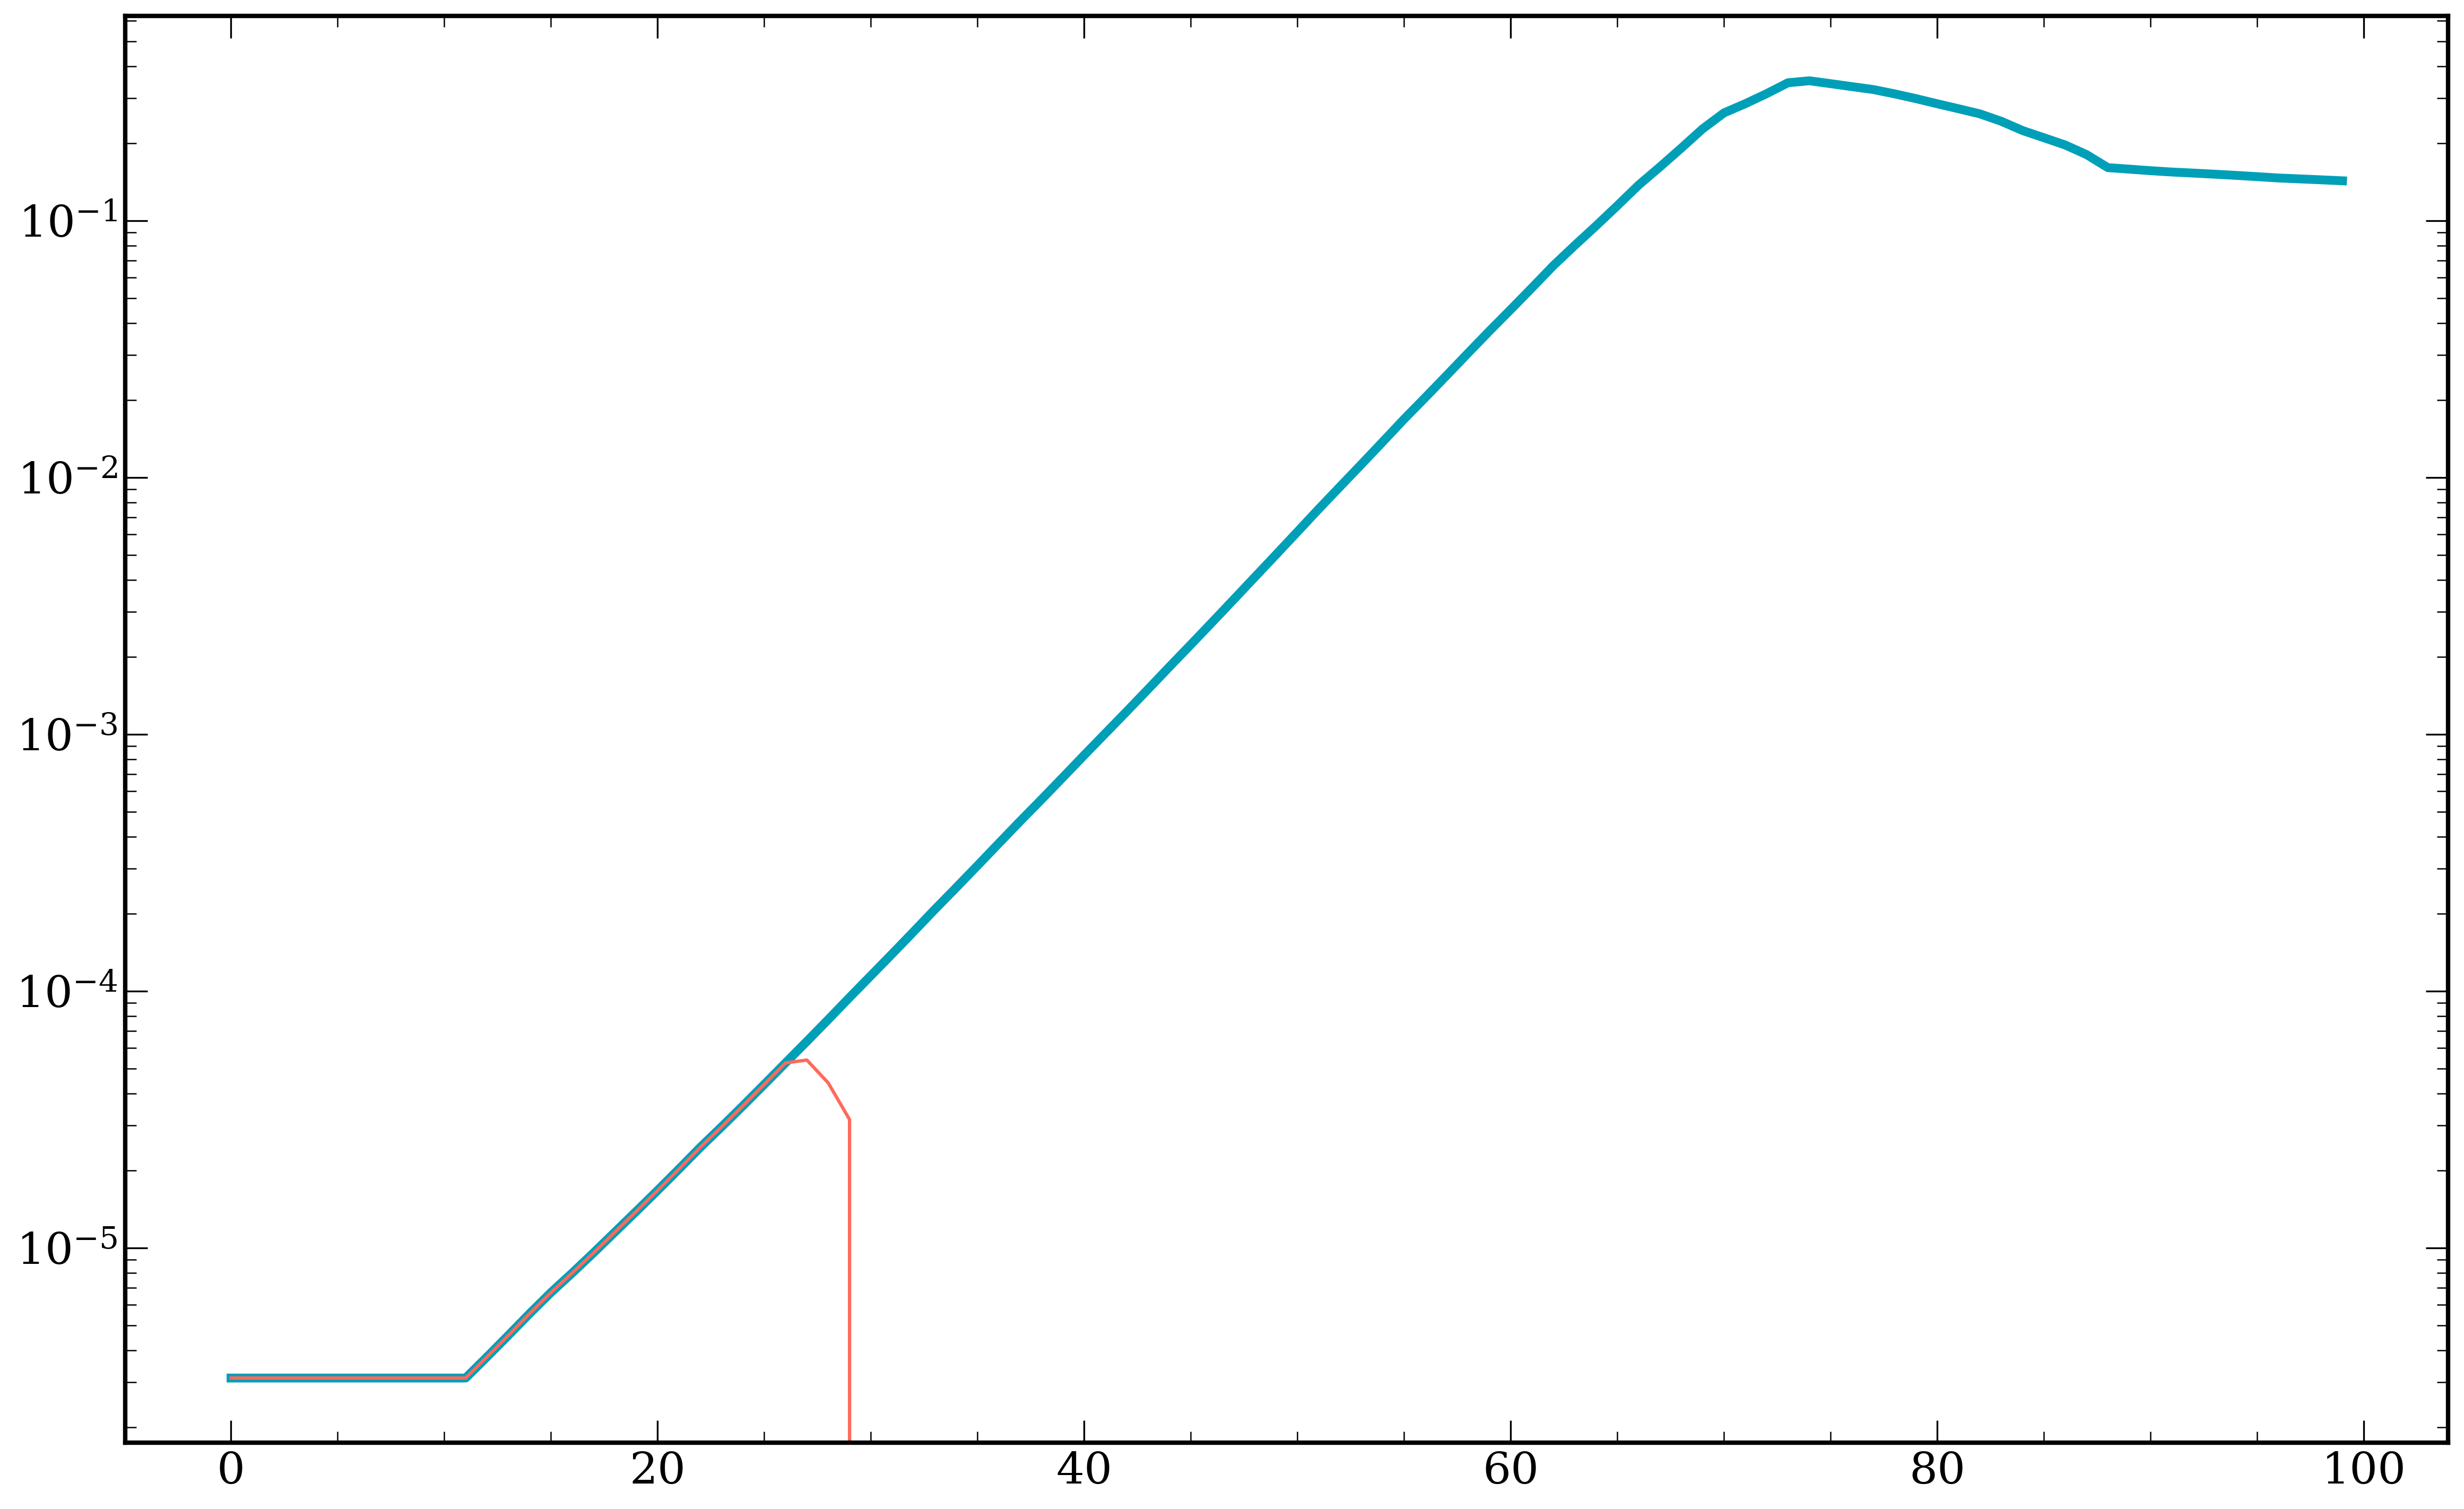

In [26]:
import matplotlib.pyplot as plt
plt.plot(interpolated_opacities[7,54,:],linewidth=4)
plt.plot(F_interpolated_opacities[7,54,:])
#plt.ylim(1e-20,1e-3)
plt.yscale('log')

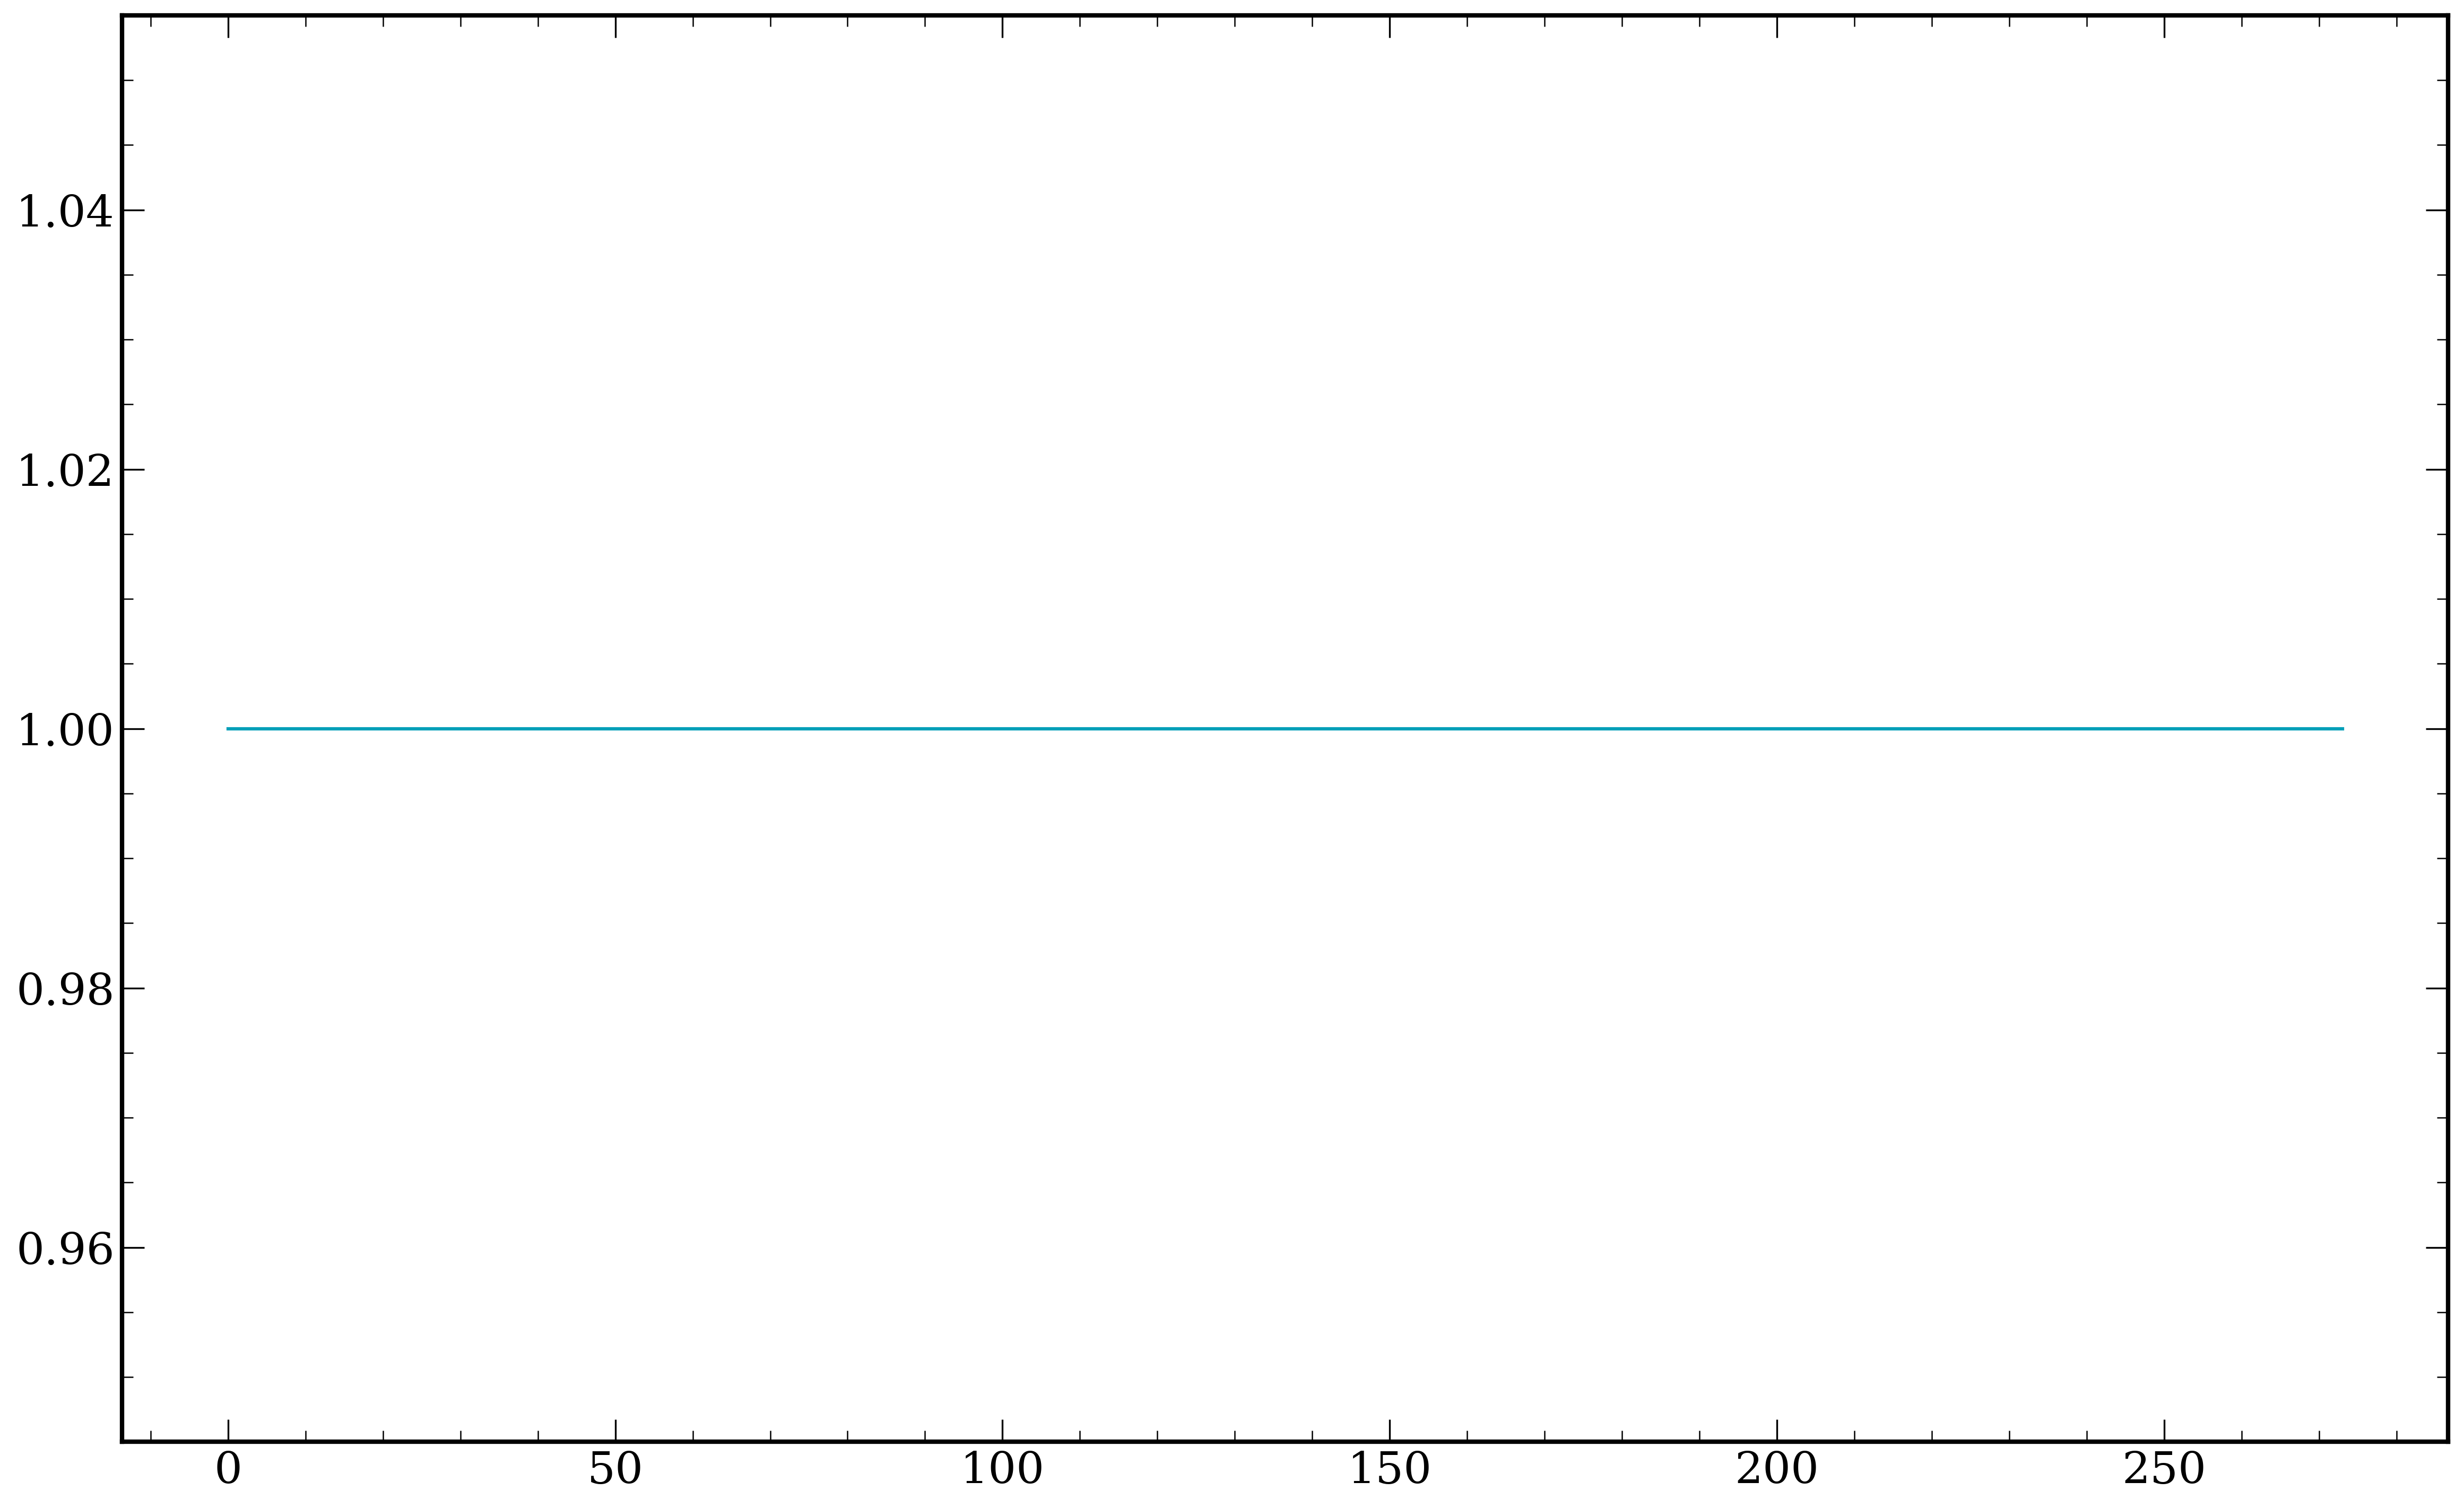

In [31]:
plt.plot(interpolated_opacities[1,:,20]/F_interpolated_opacities[1,:,20])

In [308]:
jnp.nanmax(interpolated_opacities/F_interpolated_opacities)

Array(267.50703462, dtype=float64)

In [48]:
from jax import lax

#@jit
"""
def combine_ck_opacities(opacities, g_gauss, weights_gauss):
    #JAX function to mix c-k opacities.

    #Args:
    #    opacities: (n_g, n_frequencies, n_species, n_layers) array of opacities.
    #    g_gauss: (n_g,) array of Gauss-Legendre points.
    #    weights_gauss: (n_g,) array of Gauss-Legendre weights.

    #Returns:
    #    opacities_out: (n_g, n_frequencies, n_layers) array of combined opacities.
    
    threshold_coefficient = 1e-2
    n_g, n_frequencies, n_species, n_layers = opacities.shape
    n_sample = n_g ** 2

    # Adjust weights (Fortran 1:8 indexing is 0:7 in Python)
    weights_use = weights_gauss.at[0:8].divide(3)

    # Threshold calculation (using maximum along species axis)
    threshold = jnp.max(opacities[:, :, :, :], axis=2) * threshold_coefficient

    # Precompute combined g-weights (outer product)
    g_presort = jnp.outer(weights_gauss, weights_gauss).flatten()

    # Initialize output array
    opacities_out = opacities[:, :, 0, :]  # Take the first species' opacities
    # Vectorized functions for later use
    outer_add = vmap(vmap(jnp.add, in_axes=(None, 0)), in_axes=(0, None))
    cumsum = vmap(jnp.cumsum)
    import jax.numpy as jn
"""
config.update("jax_enable_x64", True)

@jit
def combine_ck_opacities(opacities, g_gauss, weights_gauss):
    """JAX function to mix c-k opacities.

    Args:
        opacities: (n_g, n_frequencies, n_species, n_layers) array of opacities.
        g_gauss: (n_g,) array of Gauss-Legendre points.
        weights_gauss: (n_g,) array of Gauss-Legendre weights.

    Returns:
        opacities_out: (n_g, n_frequencies, n_layers) array of combined opacities.
    """

    threshold_coefficient = 1e-2
    n_g, n_frequencies, n_species, n_layers = opacities.shape

    # Threshold calculation (using maximum along species axis)
    threshold = jnp.max(opacities, axis=2) * threshold_coefficient

    # Precompute combined g-weights (outer product)
    g_presort = jnp.outer(weights_gauss, weights_gauss).flatten()
    # Initialize output array using the first species
      
    opacities_out = opacities[:, :, 0, :]
    for i_spec in range(1, n_species):  # Start from the second species
        for i_freq in range(n_frequencies):
            for i_struc in range(n_layers):
                spec2 = opacities[:, i_freq, i_spec, i_struc]
                # Combine opacities
                k_out = opacities_out[:, i_freq, i_struc, None] + spec2[None, :]

                # Flatten and sort
                k_out_flat = k_out.flatten()
                sorted_indices = jnp.argsort(k_out_flat)

                # Combine and sort
                sorted_k_out = k_out_flat[sorted_indices]

                # Sort weights
                sorted_weights = g_presort[sorted_indices]
                normalized_weights = sorted_weights / jnp.sum(sorted_weights)

                # Calculate g_out and k_out
                cumsum_weights = jnp.cumsum(normalized_weights) - normalized_weights[0]
                g_out = jnp.concatenate([cumsum_weights + (normalized_weights * 0.5),
                                        jnp.array([1.0])])
                k_out = jnp.concatenate([jnp.array([opacities_out[0, i_freq, i_struc] + spec2[0]]), 
                                        sorted_k_out[:-1], 
                                        jnp.array([opacities_out[-1, i_freq, i_struc] + spec2[-1]])])

                # Interpolate using jax.numpy.interp
                opacities_out = opacities_out.at[:, i_freq, i_struc].set(jnp.interp(g_gauss, 
                                                                                    g_out, 
                                                                                    k_out, 
                                                                                    left=opacities_out[0, i_freq, i_struc] + spec2[0], 
                                                                                    right=opacities_out[-1, i_freq, i_struc] + spec2[-1]
                                                                                    )
                                                                                )
                
    return opacities_out
    
@jit
def _combine_single_pair_k_distributions(
    current_k_dist_slice, 
    next_species_k_dist_slice, 
    g_gauss, 
    g_presort
):
    """
    Combines two k-distributions for a single frequency and layer.
    This function replicates the core logic from the original inner loops.

    Args:
        current_k_dist_slice: (n_g,) array, k-values from already mixed species.
        next_species_k_dist_slice: (n_g,) array, k-values for the next species to mix.
        g_gauss: (n_g,) array of Gauss-Legendre points (target g-values for output).
        g_presort: (n_g*n_g,) array of pre-sorted Gaussian weights (outer product of
                   original weights_gauss with itself, flattened).

    Returns:
        mixed_k_dist_slice: (n_g,) array, the new combined k-distribution.
    """
    # Combine opacities: k_ij = k_current_i + k_next_j
    k_combined_matrix = current_k_dist_slice[:, None] + next_species_k_dist_slice[None, :] 
    k_combined_flat = k_combined_matrix.flatten()

    # Sort by combined k-values
    sorted_indices = jnp.argsort(k_combined_flat)
    sorted_k_flat = k_combined_flat[sorted_indices]

    # Sort corresponding combined weights (w_i * w_j)
    sorted_combined_weights = g_presort[sorted_indices]
    
    # Normalize these combined weights so they sum to 1
    sum_sorted_combined_weights = jnp.sum(sorted_combined_weights)
    # Add epsilon to prevent division by zero if sum_weights is zero (e.g. all weights zero)
    normalized_combined_weights = sorted_combined_weights / (sum_sorted_combined_weights + 1e-12)

    # Construct xp (g_out_interp_xp) and fp (k_out_interp_fp) for jnp.interp,
    # matching the original function's logic.

    # Calculate g_out_main_part (first part of xp for interpolation)
    # This replicates: cumsum_weights = jnp.cumsum(normalized_weights) - normalized_weights[0]
    #                   g_out_pts = cumsum_weights + (normalized_weights * 0.5)
    _cumsum_val = jnp.cumsum(normalized_combined_weights)
    
    # Handle cases where normalized_combined_weights might be empty or have one element.
    # n_g >= 1 is assumed here based on checks in the main function.
    # If normalized_combined_weights has 1 element (n_g=1), _first_weight is that element.
    _first_weight = normalized_combined_weights[0]
    
    cumsum_weights_for_g_calc = _cumsum_val - _first_weight
    g_out_main_part = cumsum_weights_for_g_calc + (normalized_combined_weights * 0.5)
    
    g_out_interp_xp = jnp.concatenate([g_out_main_part, jnp.array([1.0])])

    # Calculate k_out_interp_fp (fp for interpolation)
    # Replicates: jnp.concatenate([
    #                 jnp.array([opacities_out[0,...] + spec2[0]]), 
    #                 sorted_k_out[:-1], 
    #                 jnp.array([opacities_out[-1,...] + spec2[-1]])
    #             ])
    first_k_val_interp = current_k_dist_slice[0] + next_species_k_dist_slice[0]
    last_k_val_interp = current_k_dist_slice[-1] + next_species_k_dist_slice[-1]

    if sorted_k_flat.shape[0] == 1: # Handles n_g=1 case (so n_g*n_g=1)
        # sorted_k_flat[:-1] would be empty.
        k_out_interp_fp = jnp.array([first_k_val_interp, last_k_val_interp])
    else:
        k_out_interp_fp = jnp.concatenate([
            jnp.array([first_k_val_interp]),
            sorted_k_flat[:-1],
            jnp.array([last_k_val_interp])
        ])
    
    # Interpolate
    mixed_k_dist_slice = jnp.interp(
        g_gauss,
        g_out_interp_xp,
        k_out_interp_fp,
        left=first_k_val_interp, # Value if g_gauss < min(g_out_interp_xp)
        right=last_k_val_interp   # Value if g_gauss > max(g_out_interp_xp)
    )
    return mixed_k_dist_slice

@jit
def combine_ck_opacities_vectorized(opacities, g_gauss, weights_gauss):
    """
    Vectorized JAX function to mix c-k opacities.

    Args:
        opacities: (n_g, n_frequencies, n_species, n_layers) array of opacities.
        g_gauss: (n_g,) array of Gauss-Legendre points.
        weights_gauss: (n_g,) array of Gauss-Legendre weights.

    Returns:
        opacities_out: (n_g, n_frequencies, n_layers) array of combined opacities.
    """
    n_g, n_frequencies, n_species, n_layers = opacities.shape

    # Handle edge cases
    if n_g == 0:
        return jnp.zeros((0, n_frequencies, n_layers))
    if n_species == 0:
        return jnp.zeros((n_g, n_frequencies, n_layers))
    if n_species == 1:
        return opacities[:, :, 0, :]

    # Precompute combined g-weights (outer product of weights_gauss with itself, flattened)
    # These are the w_i * w_j terms before sorting by k_ij.
    g_presort = jnp.outer(weights_gauss, weights_gauss).flatten()

    # Initial state for scan: opacities of the first species
    initial_opacities_out = opacities[:, :, 0, :]  # Shape: (n_g, n_frequencies, n_layers)

    # Data for remaining species to be scanned over
    # Shape: (n_g, n_frequencies, n_species-1, n_layers)
    opacities_remaining_species = opacities[:, :, 1:, :]
    
    # Transpose so that species is the leading dimension for scan
    # New shape: (n_species-1, n_g, n_frequencies, n_layers)
    scan_xs = jnp.moveaxis(opacities_remaining_species, 2, 0)

    # Define the scan body function
    def scan_body(carry_opacities_out_prev_species, next_species_opacities_one_species):
        # carry_opacities_out_prev_species: (n_g, n_frequencies, n_layers)
        # next_species_opacities_one_species: (n_g, n_frequencies, n_layers)

        # Transpose for vmapping: (n_g, n_freq, n_layer) -> (n_freq, n_layer, n_g)
        # This makes it easier to map over (n_freq, n_layer)
        carry_transposed = jnp.transpose(carry_opacities_out_prev_species, (1, 2, 0))
        next_spec_transposed = jnp.transpose(next_species_opacities_one_species, (1, 2, 0))

        # Vmap the core combination logic over frequencies and layers.
        # _combine_single_pair_k_distributions expects (n_g,) slices for k-dists.
        # Innermost vmap: over layers. Input slices are (n_g,)
        #   Input to this vmap: (n_layers, n_g), (n_layers, n_g) -> Output: (n_layers, n_g)
        vmapped_over_layers = vmap(
            _combine_single_pair_k_distributions, 
            in_axes=(0, 0, None, None),  # Map over axis 0 of inputs; g_gauss, g_presort are static
            out_axes=0
        )

        # Outer vmap: over frequencies. Input slices are (n_layers, n_g)
        #   Input to this vmap: (n_freq, n_layers, n_g), (n_freq, n_layers, n_g) -> Output: (n_freq, n_layers, n_g)
        vmapped_over_freq_layers = vmap(
            vmapped_over_layers,
            in_axes=(0, 0, None, None), # Map over axis 0 of inputs; g_gauss, g_presort are static (passed down)
            out_axes=0
        )
        
        combined_transposed = vmapped_over_freq_layers(
            carry_transposed, next_spec_transposed, g_gauss, g_presort
        )
        # combined_transposed has shape (n_frequencies, n_layers, n_g)

        # Transpose back: (n_frequencies, n_layers, n_g) -> (n_g, n_frequencies, n_layers)
        new_opacities_out = jnp.transpose(combined_transposed, (2, 0, 1))
        
        # scan returns (new_carry, y_element_for_stacking)
        # We only need the final carry, but can return new_opacities_out for y as well.
        return new_opacities_out, new_opacities_out

    # Run the scan
    final_opacities_out, _ = lax.scan(
        scan_body,
        initial_opacities_out,
        scan_xs 
    )
    
    return final_opacities_out

@jit
def combine_ck_opacities_gem(opacities_fortran_order, g_gauss, weights_gauss):
    """
    JAX implementation of the combine_ck_opacities Fortran subroutine.

    Args:
        opacities_fortran_order (jax.Array): Opacities with shape (n_g, n_frequencies, n_species, n_layers).
        g_gauss (jax.Array): Gaussian quadrature g-values, shape (n_g,).
        weights_gauss (jax.Array): Gaussian quadrature weights, shape (n_g,).

    Returns:
        jax.Array: Combined opacities, shape (n_g, n_frequencies, n_layers).
    """
    n_g, n_frequencies, n_species, n_layers = opacities_fortran_order.shape

    # Determine the computation dtype from g_gauss for consistency
    # This assumes g_gauss, weights_gauss, and opacities_fortran_order share the same precision needs.
    # JAX's x64 mode should be enabled upstream if float64 is desired.
    # e.g., from jax import config; config.update("jax_enable_x64", True)
    dtype = g_gauss.dtype

    threshold_coefficient = 1e-2  # Fortran: 1d-2 (Python float, JAX handles promotion)
    #n_sample = n_g * n_g

    # Threshold calculation: threshold(n_frequencies, n_layers)
    threshold = jnp.max(opacities_fortran_order[0, :, :, :], axis=1) * threshold_coefficient
    # threshold shape is (n_frequencies, n_layers)

    # g_presort calculation: flat array of weights_gauss(i) * weights_gauss(j)
    g_presort_flat = (weights_gauss[:, None] * weights_gauss[None, :]).ravel()
    # g_presort_flat shape: (n_g*n_g,) which is n_sample

    # Permute opacities for easier vmap/scan: (layers, frequencies, species, n_g)
    opacities_perm = jnp.transpose(opacities_fortran_order, (3, 1, 2, 0))
    # Permute threshold to (layers, frequencies)
    threshold_perm = jnp.transpose(threshold, (1, 0))

    def combine_one_species_lf(opac_out_current_lf, spec_opac_lf, threshold_lf):
        """
        Combines opacities of one species with the current accumulated opacities
        for a single layer and frequency.
        opac_out_current_lf: shape (n_g,)
        spec_opac_lf: shape (n_g,)
        threshold_lf: scalar
        """

        def perform_combination():
            k_out_combined_flat = (opac_out_current_lf[:, None] + spec_opac_lf[None, :]).ravel()

            sampled_opa_weights_0 = k_out_combined_flat
            sampled_opa_weights_1 = g_presort_flat

            # OPTIMIZATION: Use jax.lax.sort
            # Sort by opacities (sampled_opa_weights_0 are keys)
            k_sorted, weights_sorted = lax.sort(
                operand=[sampled_opa_weights_0, sampled_opa_weights_1],
                dimension=0,  # Sort along the 0-th axis of these 1D arrays
                num_keys=1    # Sort based on the first operand (sampled_opa_weights_0)
            )

            weights_normalized = weights_sorted / jnp.sum(weights_sorted)

            cum_sum_weights_normalized = jnp.cumsum(weights_normalized)
            # OPTIMIZATION: Explicit dtype for literals
            prev_cum_sum = jnp.concatenate([jnp.array([0.0], dtype=dtype), cum_sum_weights_normalized[:-1]])
            g_x_vals = weights_normalized * 0.5 + prev_cum_sum
            g_x_coords = jnp.concatenate([g_x_vals, jnp.array([1.0], dtype=dtype)])

            k_y_intermediate = k_sorted.at[0].set(opac_out_current_lf[0] + spec_opac_lf[0])
            k_y_coords = jnp.concatenate([
                k_y_intermediate,
                jnp.array([opac_out_current_lf[-1] + spec_opac_lf[-1]], dtype=dtype)
            ])

            new_opac_out_lf = jnp.interp(g_gauss, g_x_coords, k_y_coords)
            return new_opac_out_lf

        def skip_combination():
            return opac_out_current_lf

        return lax.cond(spec_opac_lf[-1] < threshold_lf,
                        skip_combination,
                        perform_combination)

    def process_layer_freq(opacities_all_species_lf, threshold_lf):
        opac_out_initial_lf = opacities_all_species_lf[0, :]

        # This Python if is fine for JIT as n_species is static for a given trace
        if n_species == 1:
            return opac_out_initial_lf

        def species_scan_body(current_combined_opac_lf, next_species_opac_lf):
            updated_opac_lf = combine_one_species_lf(
                current_combined_opac_lf,
                next_species_opac_lf,
                threshold_lf
            )
            return updated_opac_lf, None

        remaining_species_opac_lf = opacities_all_species_lf[1:, :]

        final_combined_opac_lf, _ = lax.scan(
            species_scan_body,
            opac_out_initial_lf,
            remaining_species_opac_lf
        )
        return final_combined_opac_lf

    opacities_out_perm = vmap(  # vmap over layers
        vmap(process_layer_freq, in_axes=(0, 0)),  # vmap over frequencies
        in_axes=(0, 0)
    )(opacities_perm, threshold_perm)

    opacities_out_final = jnp.transpose(opacities_out_perm, (2, 1, 0))

    return opacities_out_final


In [50]:
import jax.random as jrandom

key = jrandom.PRNGKey(42)  # For reproducibility

# Example data shapes (adjust these to your actual dimensions)
n_g = 16
n_frequencies = 10
n_species = 3
n_layers = 5

# Generate random opacities (you'd likely load these from data)
opacities = jrandom.uniform(key, (n_g, n_frequencies, n_species, n_layers))

# Gauss-Legendre points and weights (you can use specialized functions to get accurate values)
g_gauss = jnp.array(buffer[:,0])
weights_gauss= jnp.array(buffer[:,1])


# Call the function
combined_opacities  = combine_ck_opacities(opacities, g_gauss, weights_gauss)
vec_combined_opacities = combine_ck_opacities_vectorized(opacities, g_gauss, weights_gauss)
gem_combined_opacities = combine_ck_opacities_gem(opacities, g_gauss, weights_gauss)
#print(combined_opacities.shape,vec_combined_opacities.shape)


In [51]:
%%timeit
vec_combined_opacities = combine_ck_opacities_vectorized(opacities, g_gauss, weights_gauss)


3.18 ms ± 207 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [52]:
%%timeit
combined_opacities  = combine_ck_opacities(opacities, g_gauss, weights_gauss)


3.73 ms ± 503 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [53]:
%%timeit
gem_combined_opacities = combine_ck_opacities_gem(opacities, g_gauss, weights_gauss)


3.07 ms ± 147 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [54]:
%%timeit
F_combined_opacities = fs.combine_ck_opacities(np.array(opacities), buffer[:,0], buffer[:,1])


457 μs ± 126 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [55]:
np.mean(combined_opacities/F_combined_opacities)

Array(0.98374147, dtype=float64)

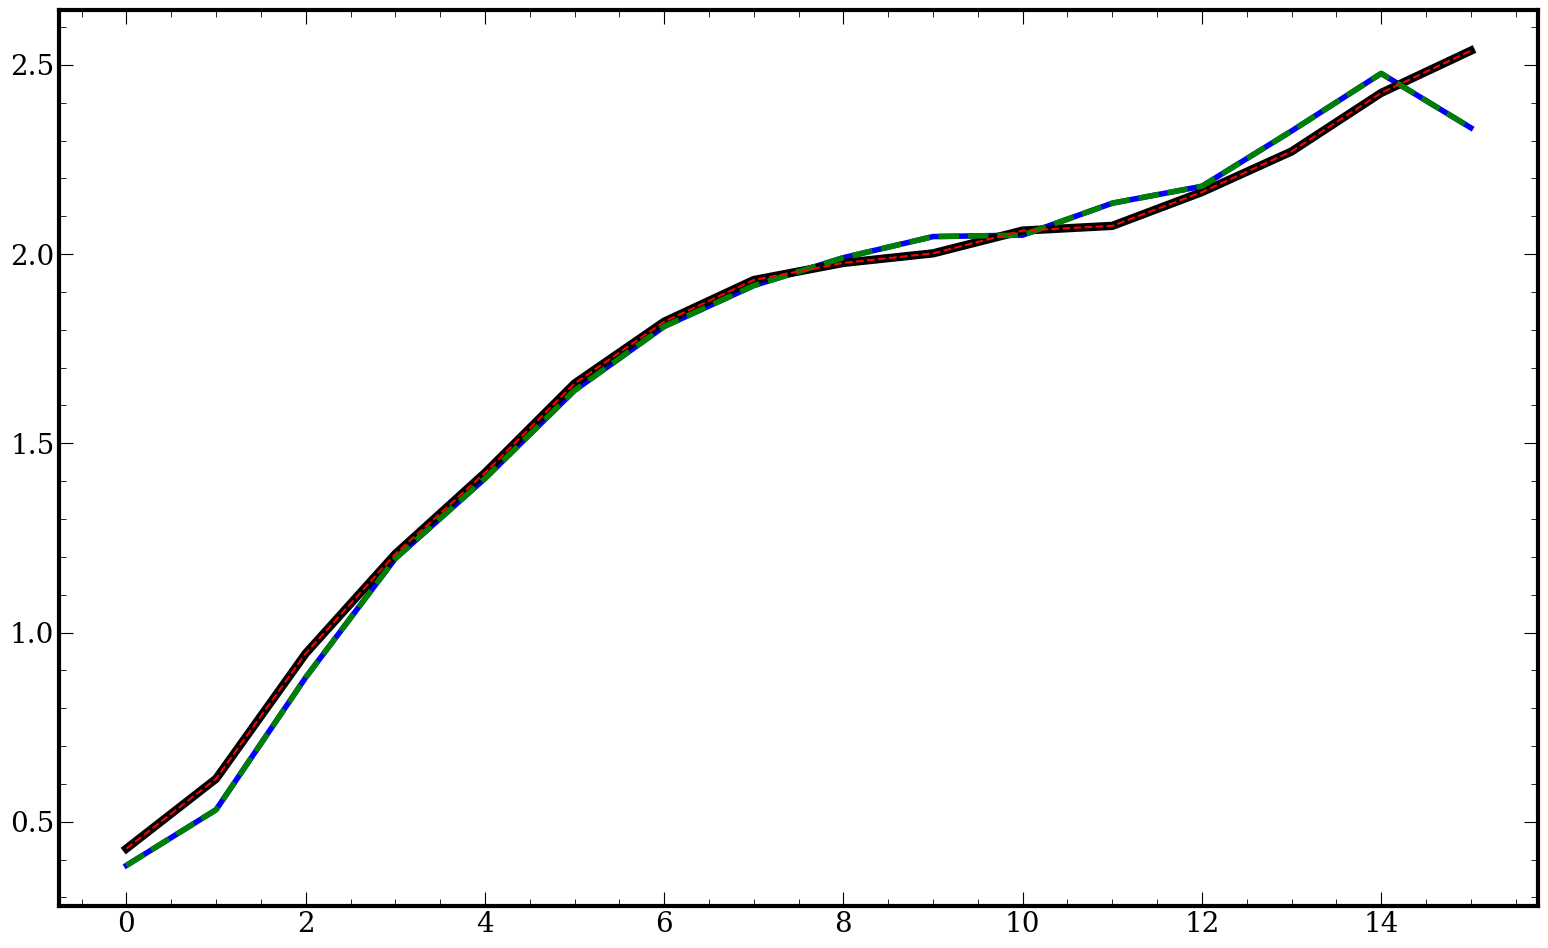

In [56]:
plt.plot(combined_opacities[:,4,0], linewidth=4, label='JAX',color='blue')
plt.plot(F_combined_opacities[:,4,0], color='k',linewidth=6)
plt.plot(vec_combined_opacities[:,4,0], linewidth=4,color='green', linestyle='--')
plt.plot(gem_combined_opacities[:,4,0],color='red', linestyle = '--')


In [371]:
print(weights_gauss)
print(0.04555284*0.04555284)


[0.04555284 0.10007147 0.14116799 0.1632077  0.1632077  0.14116799
 0.10007147 0.04555284 0.00506143 0.01111905 0.01568533 0.01813419
 0.01813419 0.01568533 0.01111905 0.00506143]
0.0020750612320656


In [199]:
arr = np.linspace(1,15,15)
print(arr)

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15.]


In [200]:
combined = arr[:,None] + arr[None,:]
print(combined.flatten())

[ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16.  3.  4.  5.
  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.  4.  5.  6.  7.  8.  9.
 10. 11. 12. 13. 14. 15. 16. 17. 18.  5.  6.  7.  8.  9. 10. 11. 12. 13.
 14. 15. 16. 17. 18. 19.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18. 19. 20. 21.
  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18. 19. 20. 21. 22.  9. 10. 11.
 12. 13. 14. 15. 16. 17. 18. 19. 20. 21. 22. 23. 10. 11. 12. 13. 14. 15.
 16. 17. 18. 19. 20. 21. 22. 23. 24. 11. 12. 13. 14. 15. 16. 17. 18. 19.
 20. 21. 22. 23. 24. 25. 12. 13. 14. 15. 16. 17. 18. 19. 20. 21. 22. 23.
 24. 25. 26. 13. 14. 15. 16. 17. 18. 19. 20. 21. 22. 23. 24. 25. 26. 27.
 14. 15. 16. 17. 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 16. 17. 18. 19. 20. 21.
 22. 23. 24. 25. 26. 27. 28. 29. 30.]
